# Projection: t2m: Data Analysis

### Why this notebook matters

This notebook demonstrates a climate-dynamics diagnostic linking ITCZ position shifts to precipitation trends under warming, combining a custom ITCZ position metric with trend mapping.

**Purpose** - Investigate the response of the Inter-Tropical Convergence Zone (ITCZ) and precipitation (`tprate`) to warming in a 2020-2039 storm-resolving projection: trend maps, ITCZ position metrics, and temperature-precipitation relationships.

**Required input data** - Monthly 2m temperature and precipitation (`tprate`) NetCDF files on the HEALPix grid under `{PROJ2559_DIR}` (originally on DKRZ Levante; not included in this repository).

**Expected outputs** - ITCZ position trend plots and precipitation/temperature relationship figures.

## Key techniques demonstrated

- Custom ITCZ position-tracking metric
- Precipitation trend mapping
- Dask-backed processing
- HEALPix handling with healpy
- Cartopy + cmocean mapping

In [ ]:
# --- Data location placeholders ---------------------------------------------
# The original analysis ran on DKRZ Levante. Input data are NOT included in
# this repository. Set this path to your own data copy before running:
#
# PROJ2559_DIR : root of the projection experiment (2020-2039)

PROJ2559_DIR = "/path/to/proj2559"  # <-- EDIT before running

## Installation & loading packages

In [1]:
import os
import numpy as np
import numpy as np
import xarray as xr
import healpy as hp
import eccodes
import cmocean as cmo
import matplotlib.cm as cm
import matplotlib.pyplot as plt

import dask.array as da
import os

# sfc variable: t2m

## Trend plot: 2020 - 2039

In [4]:
# # Load the data 'annual means' 

# # Directory where annual mean files are stored
# annual_means_dir = f"{PROJ2559_DIR}/sfc_hr/annual_means/"

# # Initialize a list to store annual mean data
# annual_means = []

# # Loop through each year from 2020 to 2039
# for year in range(2020, 2040):
#     # Load the annual mean data for the year
#     annual_mean_data = xr.open_dataset(f"{annual_means_dir}annual_mean_t2m_{year}.nc")
    
#     # Extract the t2m variable
#     annual_mean = annual_mean_data["t2m"]  # Shape: (values,)
    
#     # Append the annual mean to the list
#     annual_means.append(annual_mean)

# # Combine the annual means into a single xarray.DataArray
# annual_means = xr.concat(annual_means, dim="year")

In [5]:
# from scipy.stats import linregress

# # Create an array to store the trend values (slopes)
# trend_values = np.zeros(annual_means.shape[1])  # Shape: (values,)

# # Loop through each grid point
# for i in range(annual_means.shape[1]):
#     # Extract the time series for the current grid point
#     time_series = annual_means[:, i].values  # Shape: (years,)
    
#     # Perform linear regression
#     slope, _, _, _, _ = linregress(np.arange(len(time_series)), time_series)
    
#     # Store the slope (trend) in Â°C/year
#     trend_values[i] = slope

# # Convert the trend values to an xarray.DataArray
# trend_map = xr.DataArray(
#     trend_values,
#     dims=["values"],
#     coords={"values": annual_means["values"]},
#     attrs={"units": "Â°C/year"},
# )

# # Save the trend map to a NetCDF file (optional)
# trend_map.to_dataset(name="t2m_trend").to_netcdf(f"{PROJ2559_DIR}/sfc_hr/t2m_trend_2020_2039.nc")

In [7]:
# Load the trend map for 2020â€“2039 (alrready saved as .nc file)
trend_map = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_trend_2020_2039.nc")["t2m_trend"]

# Extract the HEALPix map (1D array)
trend_healpix_map = trend_map.values

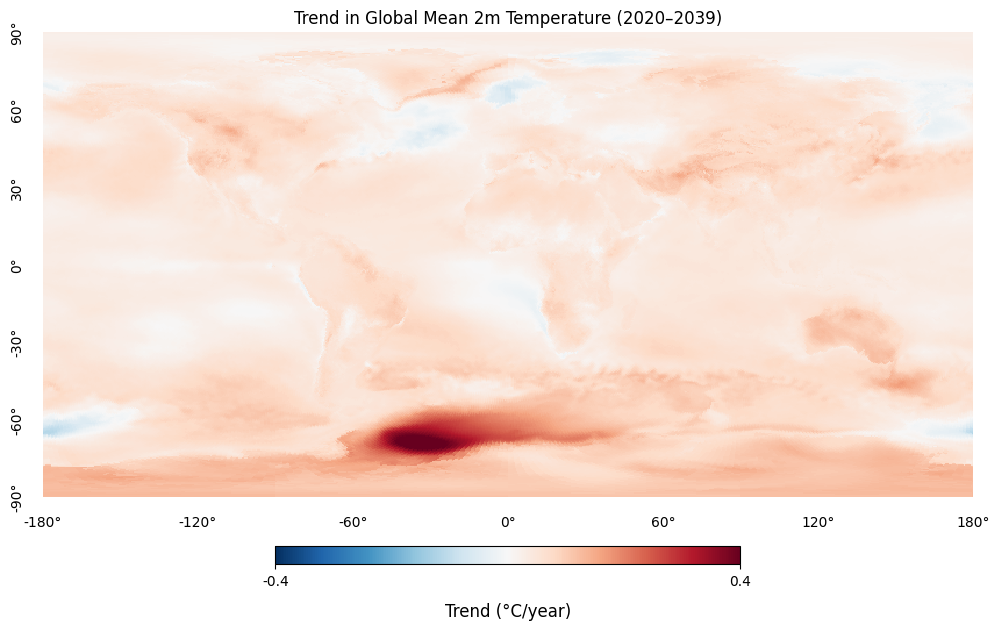

In [8]:
# Plot cartesian view

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the trend map using Healpy's cartview
hp.cartview(
    trend_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Trend in Global Mean 2m Temperature (2020â€“2039)",
    min=-0.4,            # Minimum value for the color scale (auto if None)
    max=0.4,            # Maximum value for the color scale (auto if None)
    cmap="RdBu_r",       # Colormap (red-blue for positive-negative trends)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Trend (Â°C/year)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

# Extremes

## Hotspots

In [9]:
import xarray as xr

# Load the trend map for 2020â€“2039
trend_map = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_trend_2020_2039.nc")["t2m_trend"]

# Extract the HEALPix map (1D array)
trend_healpix_map = trend_map.values

In [10]:
# Verify HEALPix Data

import healpy as hp
import numpy as np

# Get the HEALPix resolution (NSIDE) from the trend_map
nside = hp.npix2nside(len(trend_healpix_map))  # Number of pixels = len(trend_healpix_map)
print(f"HEALPix NSIDE: {nside}")
print(f"Number of pixels: {len(trend_healpix_map)}")
print(f"Trend values min: {np.min(trend_healpix_map)}, max: {np.max(trend_healpix_map)}")

HEALPix NSIDE: 128
Number of pixels: 196608
Trend values min: -0.11436760694460761, max: 0.4447082748986725


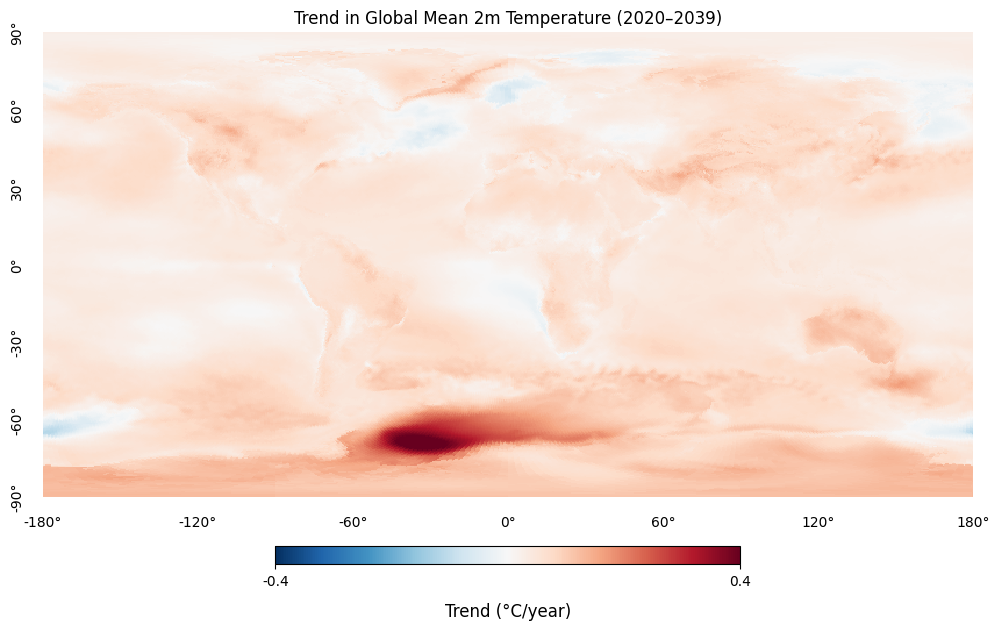

In [11]:
# Plot the Trend Map Using healpy.cartview

import matplotlib.pyplot as plt

# Create a figure
plt.figure(figsize=(12, 8))

# Plot the trend map using Healpy's cartview
hp.cartview(
    trend_healpix_map,
    flip="geo",          # Flip the map to match geographical coordinates
    nest=True,           # Use NESTED ordering (change to False if RING ordering is used)
    lonra=[-180, 180],   # Longitude range (full globe)
    latra=[-90, 90],     # Latitude range (full globe)
    title="Trend in Global Mean 2m Temperature (2020â€“2039)",
    min=-0.4,            # Minimum value for the color scale (auto if None)
    max=0.4,             # Maximum value for the color scale (auto if None)
    cmap="RdBu_r",       # Colormap (red-blue for positive-negative trends)
    badcolor="gray",     # Color for invalid/missing data
    hold=True,           # Hold the plot for further customization
)

# Add a label below the Healpy colorbar
cbar = plt.gcf().axes[-1]  # Get the last axis (colorbar)
cbar.set_xlabel("Trend (Â°C/year)", fontsize=12, labelpad=10)  # Add the unit label below the colorbar

# Add latitude and longitude labels without gridlines
lon_labels = [-180, -120, -60, 0, 60, 120, 180]
lat_labels = [-90, -60, -30, 0, 30, 60, 90]

# Add longitude labels below the map
for lon in lon_labels:
    plt.text(lon, -100, f"{lon}Â°", ha="center", va="center", fontsize=10, color="black")

# Add latitude labels to the left of the map
for lat in lat_labels:
    plt.text(-190, lat, f"{lat}Â°", ha="center", va="center", fontsize=10, color="black", rotation=90)

# Manually adjust the layout to avoid clipping
plt.subplots_adjust(left=0.1, right=0.9, bottom=0.1, top=0.9)  # Adjust margins as needed

# Show the plot
plt.show()

In [16]:
# Create a regular latitude/longitude grid

grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 180), np.linspace(-180, 180, 360))

# Convert HEALPix data to a regular grid using bilinear interpolation
grid_trend = np.zeros_like(grid_lat)
for i in range(grid_lat.shape[0]):
    for j in range(grid_lat.shape[1]):
        # Ensure longitude is in the range [-180, 180]
        lon = grid_lon[i, j]
        if lon > 180:
            lon -= 360
        grid_trend[i, j] = hp.get_interp_val(trend_healpix_map, lon, grid_lat[i, j], lonlat=True, nest=True)

# Check the interpolated data
print(f"Interpolated trend values min: {np.nanmin(grid_trend)}, max: {np.nanmax(grid_trend)}")

Interpolated trend values min: -0.11289309854428922, max: 0.44357200913930095


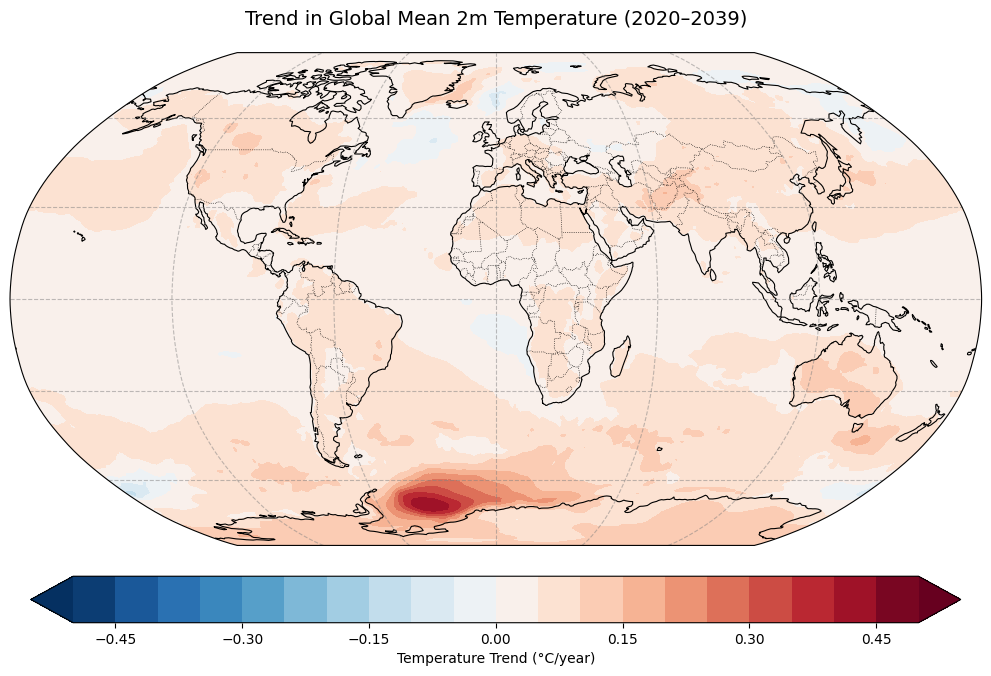

In [15]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Create figure
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# --- Plot Temperature Trend ---
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# --- Add Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Add Colorbar ---
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

# --- Add Title ---
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039)", fontsize=14, pad=20)
plt.show()


## Warm

In [17]:
# Define the Positive Hotspot Mask

# Define the threshold for positive hotspots
positive_threshold = 0.1  # Â°C/year

# Create a mask for positive hotspots (trend >= positive_threshold)
positive_hotspot_mask = grid_trend >= positive_threshold

In [ ]:
# Normalize the Positive Hotspot Trend Values

# Define the range for shading positive hotspots (0.4 to 0.45 Â°C/year)
positive_shading_min = positive_threshold                  # 0.4
positive_shading_max = 0.45

# Normalize the positive hotspot trend values within the shading range
normalized_positive_hotspot_trend = (grid_trend - positive_shading_min) / (positive_shading_max - positive_shading_min)

# Clip values outside the range (0 to 1)
normalized_positive_hotspot_trend = np.clip(normalized_positive_hotspot_trend, 0, 1)

# Apply the positive hotspot mask
# Overlay the Positive Hotspots on the Trend Mapnormalized_positive_hotspot_trend[~positive_hotspot_mask] = np.nan  # Set non-hotspots to NaN

In [ ]:
# Overlay the Positive Hotspots on the Trend Map

import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create a figure
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.Robinson())

# Plot the trend map
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",  # Red-blue colormap for positive/negative trends
    levels=np.linspace(-0.4, 0.4, 100),  # Color scale from -0.4 to 0.4 Â°C/year
)

# Overlay the positive hotspots
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="Greens",  # Green colormap for positive hotspots
    levels=np.linspace(0, 1, 100),  # Smooth color scale
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar for the trend map
cbar_trend = plt.colorbar(trend_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar_trend.set_label("Trend (Â°C/year)", fontsize=12)

# Add a colorbar for the positive hotspots
cbar_positive = plt.colorbar(positive_hotspot_plot, ax=ax, orientation="horizontal", pad=0.15)
cbar_positive.set_label("Positive Hotspot Trend (Â°C/year)", fontsize=12)
cbar_positive.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_positive.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])  # Actual values

# Add a title
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039) with Positive Hotspots", fontsize=14)

# Show the plot
plt.show()


# # Add a colorbar (customized placement and style)
# cbar_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # [left, bottom, width, height]

In [ ]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create figure with adjusted dimensions
fig = plt.figure(figsize=(12, 8.5))  # Slightly taller than original

ax = plt.axes(projection=ccrs.Robinson())

# --- Main Plots ---
# Temperature trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.45, 0.45, 101)
)

# Positive hotspots overlay
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="Greens",
    levels=np.linspace(0, 1, 100),
    alpha=0.5
)

# --- Map Elements ---
ax.coastlines(linewidth=0.8)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Title (positioned at top) ---
plt.title("Temperature Trends with Positive Hotspots (2020-2039)", 
          fontsize=14, pad=20, y=1.05)  # y=1.05 moves title slightly higher

# --- Colorbar 1: Temperature Trend ---
cbar_trend_ax = fig.add_axes([0.25, 0.13, 0.5, 0.02])  # Position matches your reference
cbar_trend = fig.colorbar(trend_plot, cax=cbar_trend_ax,
                         orientation="horizontal")
cbar_trend.set_label("Temperature Trend (Â°C/year)", fontsize=12)

# --- Colorbar 2: Positive Hotspots --- 
cbar_hotspot_ax = fig.add_axes([0.25, 0.05, 0.5, 0.02])  # Positioned below first
cbar_hotspot = fig.colorbar(positive_hotspot_plot, cax=cbar_hotspot_ax,
                          orientation="horizontal")
cbar_hotspot.set_label("Positive Hotspot Intensity (Normalized)", fontsize=12)
cbar_hotspot.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_hotspot.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])

# Adjust overall plot spacing
plt.subplots_adjust(top=0.85)  # Creates space for title without overlapping

plt.show()

In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np

# Create figure with adjusted dimensions
fig = plt.figure(figsize=(12, 8.5))  # Slightly taller than original
ax = plt.axes(projection=ccrs.Robinson())

# --- Main Plots ---
# Temperature trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),  # Ensures distinct contour colors
    extend="both"
)

# Positive hotspots overlay
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="PuBu_r",
    levels=np.linspace(0, 1, 21),  # Adjusted for better contrast
    alpha=0.1,
    extend="both"
)

# --- Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Title (positioned at top) ---
plt.title("Temperature Trends with Positive Hotspots (2020-2039)", 
          fontsize=14, pad=20, y=1.05)  # y=1.05 moves title slightly higher

# --- Colorbar 1: Temperature Trend ---
cbar_trend_ax = fig.add_axes([0.25, 0.13, 0.5, 0.02])  # Position matches your reference
cbar_trend = fig.colorbar(trend_plot, cax=cbar_trend_ax,
                         orientation="horizontal", extend='both')
cbar_trend.set_label("Temperature Trend (Â°C/year)", fontsize=12)

# --- Colorbar 2: Positive Hotspots --- 
cbar_hotspot_ax = fig.add_axes([0.25, 0.05, 0.5, 0.02])  # Positioned below first
cbar_hotspot = fig.colorbar(positive_hotspot_plot, cax=cbar_hotspot_ax,
                          orientation="horizontal", extend='both')
cbar_hotspot.set_label("Positive Hotspot Intensity (Normalized)", fontsize=12)
cbar_hotspot.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_hotspot.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])

# Adjust overall plot spacing
plt.subplots_adjust(top=0.85)  # Creates space for title without overlapping

plt.show()


## Warm & Cool

In [ ]:
# Define the Negative Hotspot Mask

# Define the threshold for negative hotspots
negative_threshold = -0.04  # Â°C/year

# Create a mask for negative hotspots (trend <= negative_threshold)
negative_hotspot_mask = grid_trend <= negative_threshold

In [ ]:
# Normalize the Negative Hotspot Trend Values

# Define the range for shading negative hotspots (-0.114 to -0.04 Â°C/year)
negative_shading_min = -0.114
negative_shading_max = negative_threshold             # -0.04

# Normalize the negative hotspot trend values within the shading range
normalized_negative_hotspot_trend = (grid_trend - negative_shading_min) / (negative_shading_max - negative_shading_min)

# Clip values outside the range (0 to 1)
normalized_negative_hotspot_trend = np.clip(normalized_negative_hotspot_trend, 0, 1)

# Apply the negative hotspot mask
normalized_negative_hotspot_trend[~negative_hotspot_mask] = np.nan  # Set non-hotspots to NaN

In [ ]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create figure with adjusted dimensions
fig = plt.figure(figsize=(14, 10.5))  # Increased height to accommodate colorbars
ax = plt.axes(projection=ccrs.Robinson())

# --- Main Plots ---
# Temperature trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.4, 0.4, 101)
)

# Hotspots overlays
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdPu_r",
    levels=np.linspace(0, 1, 100),
    alpha=0.2
)

negative_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_negative_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="PuBu",
    levels=np.linspace(0, 1, 100),
    alpha=0
)

# --- Map Elements ---
ax.coastlines(linewidth=0.8)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Title ---
plt.title("Trend in Global Mean 2m Temperature (2020-2039) with Hotspots", 
          fontsize=14, pad=20, y=1.02)

# --- Colorbar 1: Temperature Trend ---
cbar_trend_ax = fig.add_axes([0.25, 0.18, 0.5, 0.02])  # Highest position
cbar_trend = fig.colorbar(trend_plot, cax=cbar_trend_ax,
                        orientation="horizontal")
cbar_trend.set_label("Temperature Trend (Â°C/year)", fontsize=12)

# --- Colorbar 2: Positive Hotspots ---
cbar_pos_ax = fig.add_axes([0.25, 0.12, 0.5, 0.02])  # Middle position
cbar_pos = fig.colorbar(positive_hotspot_plot, cax=cbar_pos_ax,
                       orientation="horizontal")
cbar_pos.set_label("Positive Hotspot Intensity (Normalized)", fontsize=12)
cbar_pos.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_pos.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])

# --- Colorbar 3: Negative Hotspots ---
cbar_neg_ax = fig.add_axes([0.25, 0.06, 0.5, 0.02])  # Lowest position
cbar_neg = fig.colorbar(negative_hotspot_plot, cax=cbar_neg_ax,
                       orientation="horizontal")
cbar_neg.set_label("Negative Hotspot Intensity (Normalized)", fontsize=12)
cbar_neg.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_neg.set_ticklabels(["-0.114", "-0.10", "-0.08", "-0.06", "-0.05", "-0.04"])

# Adjust layout
plt.subplots_adjust(top=0.85, bottom=0.2)  # Creates space for title and colorbars

plt.show()

In [ ]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create a larger figure to fix the size issue
fig = plt.figure(figsize=(14, 10))  # Increased figure size
ax = plt.axes(projection=ccrs.Robinson())

# Plot the trend map
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",  # Red-blue colormap for positive/negative trends
    levels=np.linspace(-0.45, 0.45, 100),  # Color scale from -0.114 to 0.445 Â°C/year
)

# Overlay the positive hotspots
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="Greens",  # Green colormap for positive hotspots
    levels=np.linspace(0, 1, 100),  # Smooth color scale
)

# Overlay the negative hotspots
negative_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_negative_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="Reds",  # Red colormap for negative hotspots
    levels=np.linspace(0, 1, 100),  # Smooth color scale
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar for the trend map
cbar_trend = plt.colorbar(trend_plot, ax=ax, orientation="horizontal", pad=0.05, shrink=0.8)
cbar_trend.set_label("Trend (Â°C/year)", fontsize=12)

# Add a colorbar for the positive hotspots
cbar_positive = plt.colorbar(positive_hotspot_plot, ax=ax, orientation="horizontal", pad=0.15, shrink=0.8)
cbar_positive.set_label("Positive Hotspot Trend (Â°C/year)", fontsize=12)
cbar_positive.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_positive.set_ticklabels(["0.40", "0.42", "0.44", "0.46", "0.48", "0.50"])  # Actual values

# Add a colorbar for the negative hotspots
cbar_negative = plt.colorbar(negative_hotspot_plot, ax=ax, orientation="horizontal", pad=0.25, shrink=0.8)
cbar_negative.set_label("Negative Hotspot Trend (Â°C/year)", fontsize=12)
cbar_negative.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_negative.set_ticklabels(["-0.114", "-0.10", "-0.08", "-0.06", "-0.05", "-0.04"])  # Actual values

# Add a title
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039) with Hotspots", fontsize=14)

# Adjust layout to make the map larger
plt.tight_layout()

# Show the plot
plt.show()

In [ ]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create figure (using your original size)
fig = plt.figure(figsize=(14, 10))
ax = plt.axes(projection=ccrs.Robinson())

# --- Main Plots ---
# Temperature trend (unchanged)
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.45, 0.45, 101)
)

# Positive hotspots (unchanged from working version)
positive_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_positive_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdPu_r",
    levels=np.linspace(0, 1, 100)
)

# Negative hotspots (modified)
negative_hotspot_plot = ax.contourf(
    grid_lon, grid_lat, normalized_negative_hotspot_trend,
    transform=ccrs.PlateCarree(),
    cmap="PuBu",  # Using standard PuBu without _r
    levels=np.linspace(0, 1, 100)
)

# --- Map Elements ---
ax.coastlines()
ax.gridlines()

# --- Colorbar 1: Temperature Trend ---
cbar_trend_ax = fig.add_axes([0.25, 0.25, 0.5, 0.02])
cbar_trend = fig.colorbar(trend_plot, cax=cbar_trend_ax, orientation="horizontal")
cbar_trend.set_label("Trend (Â°C/year)", fontsize=12)

# --- Colorbar 2: Positive Hotspots ---
cbar_pos_ax = fig.add_axes([0.25, 0.18, 0.5, 0.02])
cbar_pos = fig.colorbar(positive_hotspot_plot, cax=cbar_pos_ax, orientation="horizontal")
cbar_pos.set_label("Positive Hotspot Trend (Â°C/year)", fontsize=12)
cbar_pos.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_pos.set_ticklabels(["0.1", "0.2", "0.3", "0.35", "0.4", "0.45"])

# --- Colorbar 3: Negative Hotspots ---
cbar_neg_ax = fig.add_axes([0.25, 0.11, 0.5, 0.02])
cbar_neg = fig.colorbar(negative_hotspot_plot, cax=cbar_neg_ax, orientation="horizontal")
cbar_neg.set_label("Negative Hotspot Trend (Â°C/year)", fontsize=12)
cbar_neg.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
cbar_neg.set_ticklabels(["-0.114", "-0.10", "-0.08", "-0.06", "-0.05", "-0.04"])

# --- Title ---
plt.title("Trend in Global Mean 2m Temperature (2020â€“2039) with Hotspots", fontsize=14)
plt.tight_layout()
plt.show()

# ITCZ 

## PPTN mean

In [3]:
# Define the output directory where monthly mean files are stored
output_dir = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_tpr/"

# # List of monthly mean files
# monthly_files = [f"{output_dir}monthly_mean_tpr_{year}.nc" for year in range(2020, 2040)]

In [4]:
import xarray as xr
import pandas as pd

# Function to add time coordinates to a dataset
def add_time_coords(ds, year):
    # Create a time coordinate for each month
    time = pd.date_range(start=f"{year}-01-01", periods=12, freq="M")
    ds = ds.assign_coords(time=time)
    return ds

# Load one monthly mean file to inspect
sample_file = f"{output_dir}monthly_mean_tprate_2020.nc"
ds_sample = xr.open_dataset(sample_file)

# Add time coordinates to the dataset
ds_sample = add_time_coords(ds_sample, 2020)

# Print the updated dataset
print(ds_sample)

<xarray.Dataset>
Dimensions:    (values: 196608, month: 12, time: 12)
Coordinates:
    step       timedelta64[ns] ...
    surface    float64 ...
    latitude   (values) float64 ...
    longitude  (values) float64 ...
  * month      (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
  * time       (time) datetime64[ns] 2020-01-31 2020-02-29 ... 2020-12-31
Dimensions without coordinates: values
Data variables:
    tprate     (month, values) float32 ...


In [5]:
# Loop through each year and add time coordinates
datasets = []
for year in range(2020, 2040):
    file_path = f"{output_dir}monthly_mean_tprate_{year}.nc"
    ds = xr.open_dataset(file_path)
    ds = add_time_coords(ds, year)
    datasets.append(ds)

# Concatenate all datasets along the time dimension
ds = xr.concat(datasets, dim="time")

# Print the concatenated dataset
print(ds)

<xarray.Dataset>
Dimensions:    (values: 196608, month: 12, time: 240)
Coordinates:
    step       timedelta64[ns] 00:00:00
    surface    float64 0.0
    latitude   (values) float64 0.2984 0.5968 0.5968 ... -0.5968 -0.5968 -0.2984
    longitude  (values) float64 45.0 45.35 44.65 45.0 ... 315.4 314.6 315.0
  * month      (month) int64 1 2 3 4 5 6 7 8 9 10 11 12
  * time       (time) datetime64[ns] 2020-01-31 2020-02-29 ... 2039-12-31
Dimensions without coordinates: values
Data variables:
    tprate     (time, month, values) float32 1.74e-06 1.926e-06 ... 1.293e-05


In [6]:
# Group by year and compute the annual mean
annual_means = ds["tprate"].groupby("time.year").mean(dim="time")

# Print the annual means
print("Annual means:")
print(annual_means)
print(annual_means.shape)

Annual means:
<xarray.DataArray 'tprate' (year: 20, month: 12, values: 196608)>
array([[[1.73986564e-06, 1.92589278e-06, 1.50021799e-06, ...,
         2.10373735e-04, 1.98912690e-04, 1.22968238e-04],
        [6.71783411e-08, 1.35684076e-07, 3.69719011e-08, ...,
         6.96036150e-05, 9.54554052e-05, 5.84559712e-05],
        [1.09560347e-06, 1.31893557e-06, 1.49145819e-06, ...,
         1.18547388e-04, 8.28589473e-05, 5.81606691e-05],
        ...,
        [1.83178181e-05, 2.21302616e-05, 1.93262986e-05, ...,
         1.29208468e-06, 1.99873307e-06, 9.67386200e-07],
        [6.46347689e-06, 8.91649051e-06, 8.71009161e-06, ...,
         2.99239605e-06, 2.76035985e-06, 3.15622060e-06],
        [1.21879827e-06, 2.12022837e-06, 9.51315940e-07, ...,
         2.54048809e-05, 3.06703769e-05, 2.93956564e-05]],

       [[1.93912896e-07, 2.58514575e-07, 2.07026474e-07, ...,
         6.71116941e-05, 8.36091567e-05, 6.69955116e-05],
        [6.30527595e-08, 1.73611284e-07, 1.32816027e-07, ...,
   

In [7]:
# Select time periods directly from the full dataset for ITCZ

period1_ds = ds.sel(time=slice("2020-01-01", "2024-12-31"))  # 2020-2024 (60 months)
period2_ds = ds.sel(time=slice("2035-01-01", "2039-12-31"))  # 2035-2039 (60 months)

# Compute mean over ALL months (collapsing both time and month dimensions)
period1_mean_all_months = period1_ds["tprate"].mean(dim=["time", "month"])  # Shape: (196608,)
period2_mean_all_months = period2_ds["tprate"].mean(dim=["time", "month"])  # Shape: (196608,)

print("2020-2024 mean shape:", period1_mean_all_months.shape)  # Should be (196608,)
print("2035-2039 mean shape:", period2_mean_all_months.shape)  # Should be (196608,)

2020-2024 mean shape: (196608,)
2035-2039 mean shape: (196608,)


In [8]:
# Convert the units to mm/day

period1_mean_mmday = period1_mean_all_months * 86400

period2_mean_mmday = period2_mean_all_months * 86400

print("2020-2024:")
print(f"Min: {np.min(period1_mean_mmday):.2f} mm/day, Max: {np.max(period1_mean_mmday):.2f} mm/day")

print("2035-2039:")
print(f"Min: {np.min(period2_mean_mmday):.2f} mm/day, Max: {np.max(period2_mean_mmday):.2f} mm/day")

2020-2024:
Min: 0.00 mm/day, Max: 42.68 mm/day
2035-2039:
Min: 0.00 mm/day, Max: 44.91 mm/day


### Plot PPTN (ITCZ periods)

In [ ]:


# # Compute the long-term mean across all years and months
# long_term_mean = ds["tcc"].mean(dim=["time", "month"])

# Plot the long-term mean using healpy.cartview
hp.cartview(
    period1_mean_mmday.values,  # HEALPix data
    nest=True,              # Use NESTED ordering
    title="Period (2020â€“2024): Precipitation",
    min=0,                  # Minimum value for the color scale
    max=10,                  # Maximum value for the color scale
    cmap="Greens",           # Colormap for cloud cover
    badcolor="gray",        # Color for invalid/missing data
    hold=True,              # Hold the plot for further customization
)

# Add latitude and longitude labels
hp.graticule()

# Show the plot
plt.show()

In [9]:
## Plot in Robinson projection

import numpy as np

# Define the target grid (180x360)
grid_lat, grid_lon = np.meshgrid(np.linspace(-90, 90, 180), np.linspace(-180, 180, 360))

In [10]:
## Interpolate to healpix

# Initialize the interpolated grid
grid_period1 = np.zeros_like(grid_lat)
grid_period2 = np.zeros_like(grid_lat)

# Perform interpolation
for i in range(grid_lat.shape[0]):
    for j in range(grid_lat.shape[1]):
        lon = grid_lon[i, j]
        lat = grid_lat[i, j]
        
        # Ensure longitude is in the range [-180, 180]
        if lon > 180:
            lon -= 360
        
        # Interpolate the HEALPix data
        grid_period1[i, j] = hp.get_interp_val(period1_mean_mmday.values, lon, lat, lonlat=True, nest=True)
        grid_period2[i, j] = hp.get_interp_val(period2_mean_mmday.values, lon, lat, lonlat=True, nest=True)

# Replace NaN values in the interpolated data
grid_period1 = np.nan_to_num(grid_period1, nan=0)
grid_period2 = np.nan_to_num(grid_period2, nan=0)

# Check the interpolated data
print(f"Interpolated Precipitation rate values (2020-2024) min: {np.nanmin(grid_period1)}, max: {np.nanmax(grid_period1)}")
print(f"Interpolated data shape: {grid_period1.shape}")
print(f"Interpolated Precipitation rate values (2035-2039) min: {np.nanmin(grid_period2)}, max: {np.nanmax(grid_period2)}")
print(f"Interpolated data shape: {grid_period2.shape}")

Interpolated Precipitation rate values (2020-2024) min: 0.0017145454854155158, max: 29.042133870208332
Interpolated data shape: (360, 180)
Interpolated Precipitation rate values (2035-2039) min: 0.0003349938774944394, max: 31.912427510038754
Interpolated data shape: (360, 180)


/tmp/ipykernel_1622582/316405111.py:44: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


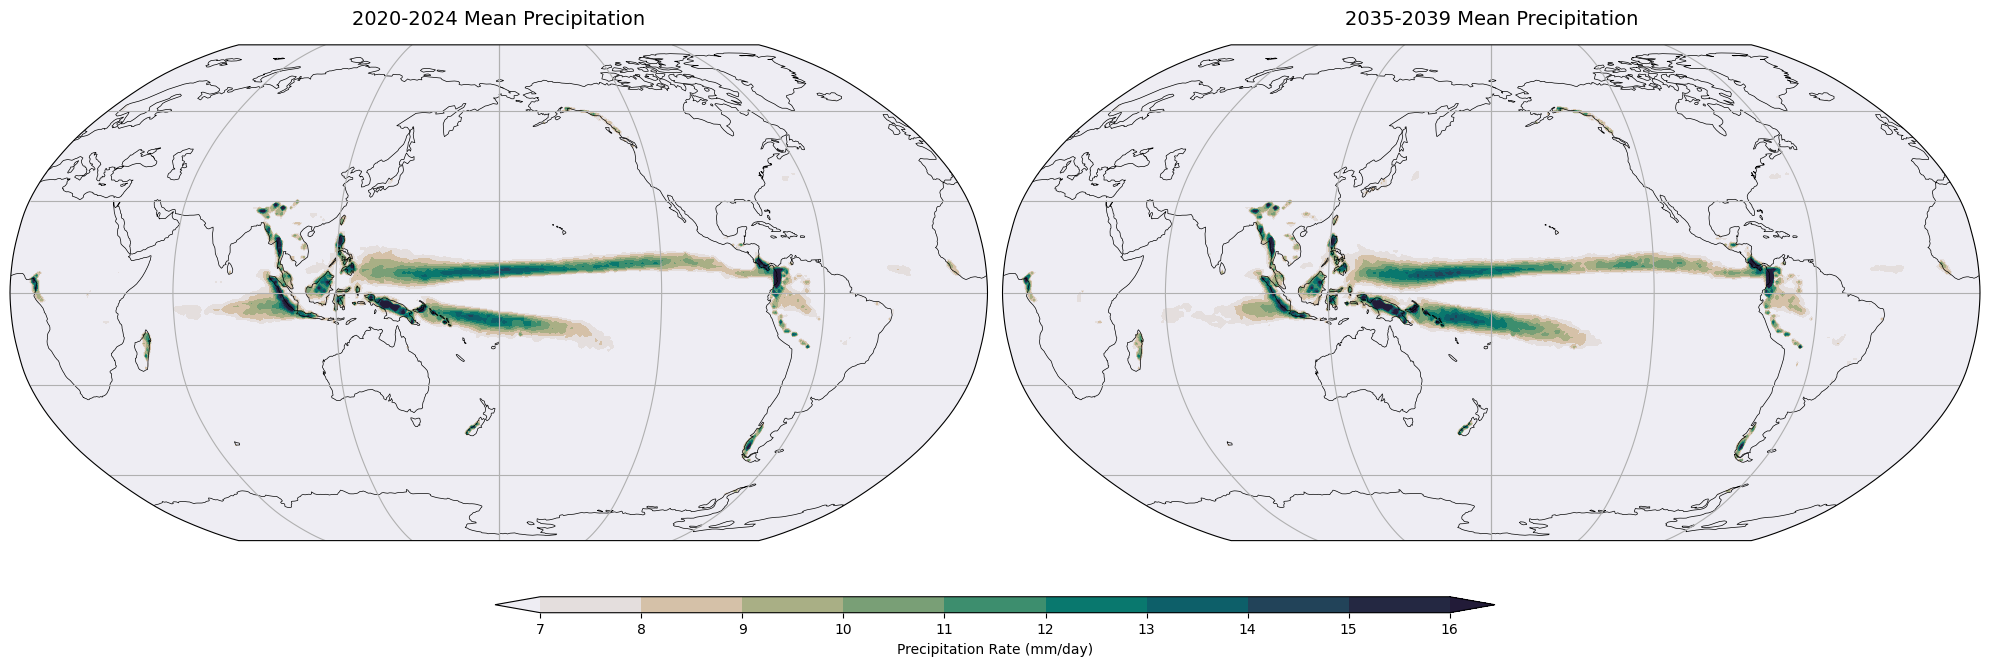

In [19]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8),
                              subplot_kw={'projection': ccrs.Robinson(central_longitude=180)})

# Common parameters for both plots
#levels = np.linspace(0, 20, 21)
levels = np.arange(7, 17, 1)
cmap = cmo.rain

# Plot first period (2020-2024)
precip1 = ax1.contourf(
    grid_lon, grid_lat, grid_period1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="both"
)
ax1.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax1.gridlines()
ax1.set_title("2020-2024 Mean Precipitation", fontsize=14, pad=15)

# Plot second period (2035-2039)
precip2 = ax2.contourf(
    grid_lon, grid_lat, grid_period2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="both"
)
ax2.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax2.gridlines()
ax2.set_title("2035-2039 Mean Precipitation", fontsize=14, pad=15)

# Add single colorbar (corrected - no fontsize parameter)
cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.02])
cbar = fig.colorbar(precip1, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Precipitation Rate (mm/day)")  # Set label after creation

plt.tight_layout()
plt.show()

/home/<username>/.local/lib/python3.10/site-packages/cartopy/mpl/geoaxes.py:1646: UserWarning: The following kwargs were not used by contour: 'label'
  result = super().contourf(*args, **kwargs)
/home/<username>/.local/lib/python3.10/site-packages/cartopy/mpl/geoaxes.py:1646: UserWarning: The following kwargs were not used by contour: 'label'
  result = super().contourf(*args, **kwargs)


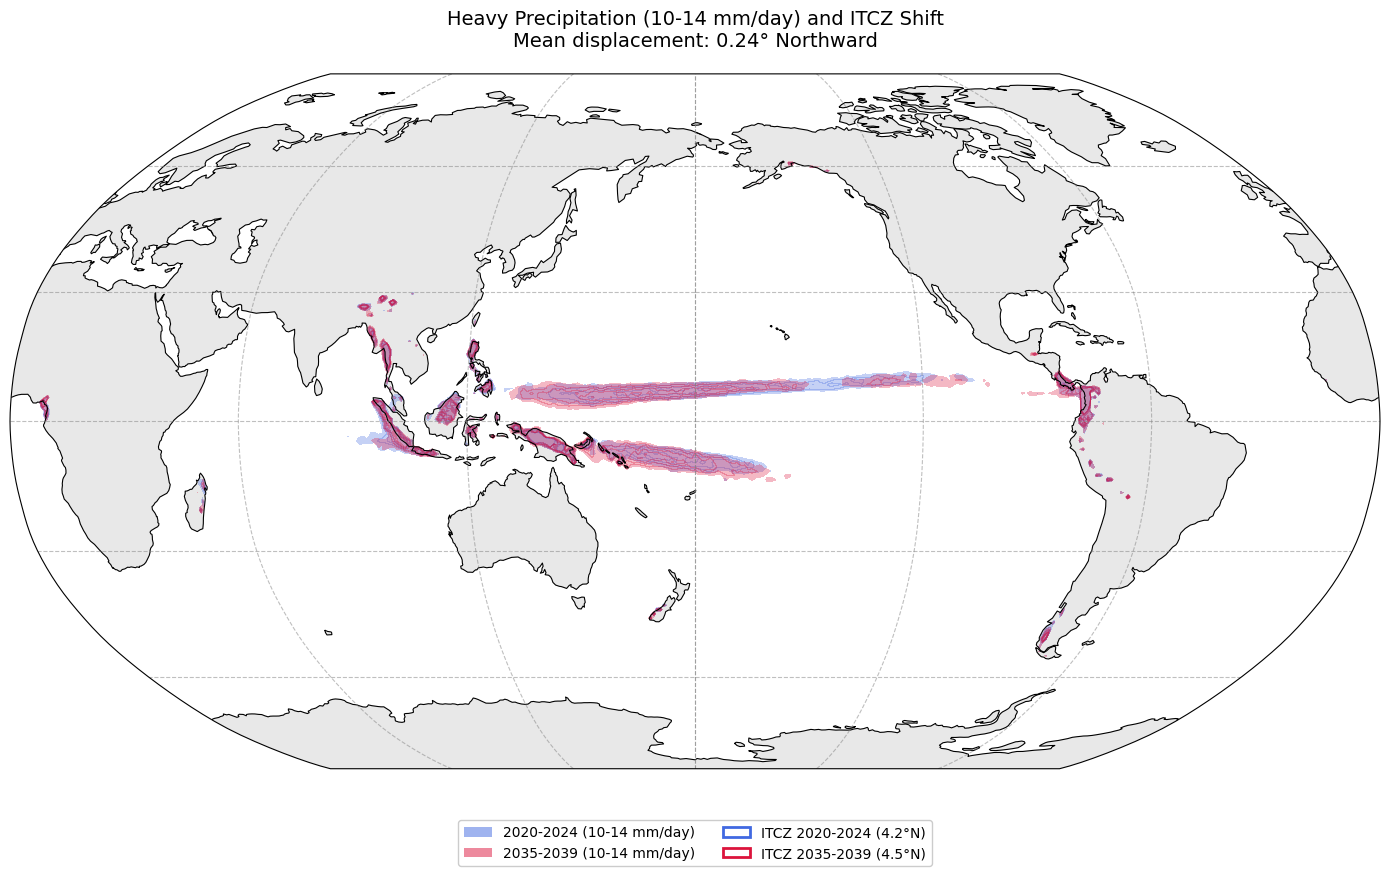

In [21]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Create single plot
fig = plt.figure(figsize=(14, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Custom contour levels
levels = np.arange(10, 15, 1)  # [10, 11, 12, 13, 14]

# --- Plot 2020-2024 contours (royalblue) ---
contour1 = ax.contourf(
    grid_lon, grid_lat, grid_period1,
    levels=levels,
    transform=ccrs.PlateCarree(),
    colors=['royalblue'],
    alpha=0.3,  # Transparency for overlap areas
    extend="max",
    label='2020-2024'
)

# --- Plot 2035-2039 contours (crimson) ---
contour2 = ax.contourf(
    grid_lon, grid_lat, grid_period2,
    levels=levels,
    transform=ccrs.PlateCarree(),
    colors=['crimson'],
    alpha=0.3,
    extend="max",
    label='2035-2039'
)

# # --- Overlay ITCZ lines ---
# ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
#         color='royalblue', linewidth=2.5, linestyle='-',
#         label=f'ITCZ 2020-2024 ({np.mean(itcz_p1):.1f}Â°N)')

# ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
#         color='crimson', linewidth=2.5, linestyle='-',
#         label=f'ITCZ 2035-2039 ({np.mean(itcz_p2):.1f}Â°N)')

# --- Map elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Legend and title ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='royalblue', alpha=0.5, label='2020-2024 (10-14 mm/day)'),
    Patch(facecolor='crimson', alpha=0.5, label='2035-2039 (10-14 mm/day)'),
    Patch(facecolor='none', edgecolor='royalblue', linewidth=2, 
          label=f'ITCZ 2020-2024 ({np.mean(itcz_p1):.1f}Â°N)'),
    Patch(facecolor='none', edgecolor='crimson', linewidth=2, 
          label=f'ITCZ 2035-2039 ({np.mean(itcz_p2):.1f}Â°N)')
]

ax.legend(handles=legend_elements, 
          loc='lower center',
          bbox_to_anchor=(0.5, -0.15),
          ncol=2,
          framealpha=1)

# --- Shift annotation ---
mean_shift = np.mean(itcz_p2 - itcz_p1)
shift_dir = "North" if mean_shift >= 0 else "South"
plt.title(f"Heavy Precipitation (10-14 mm/day) and ITCZ Shift\n"
          f"Mean displacement: {abs(mean_shift):.2f}Â° {shift_dir}ward", 
          fontsize=14, pad=20)

plt.tight_layout()
plt.show()

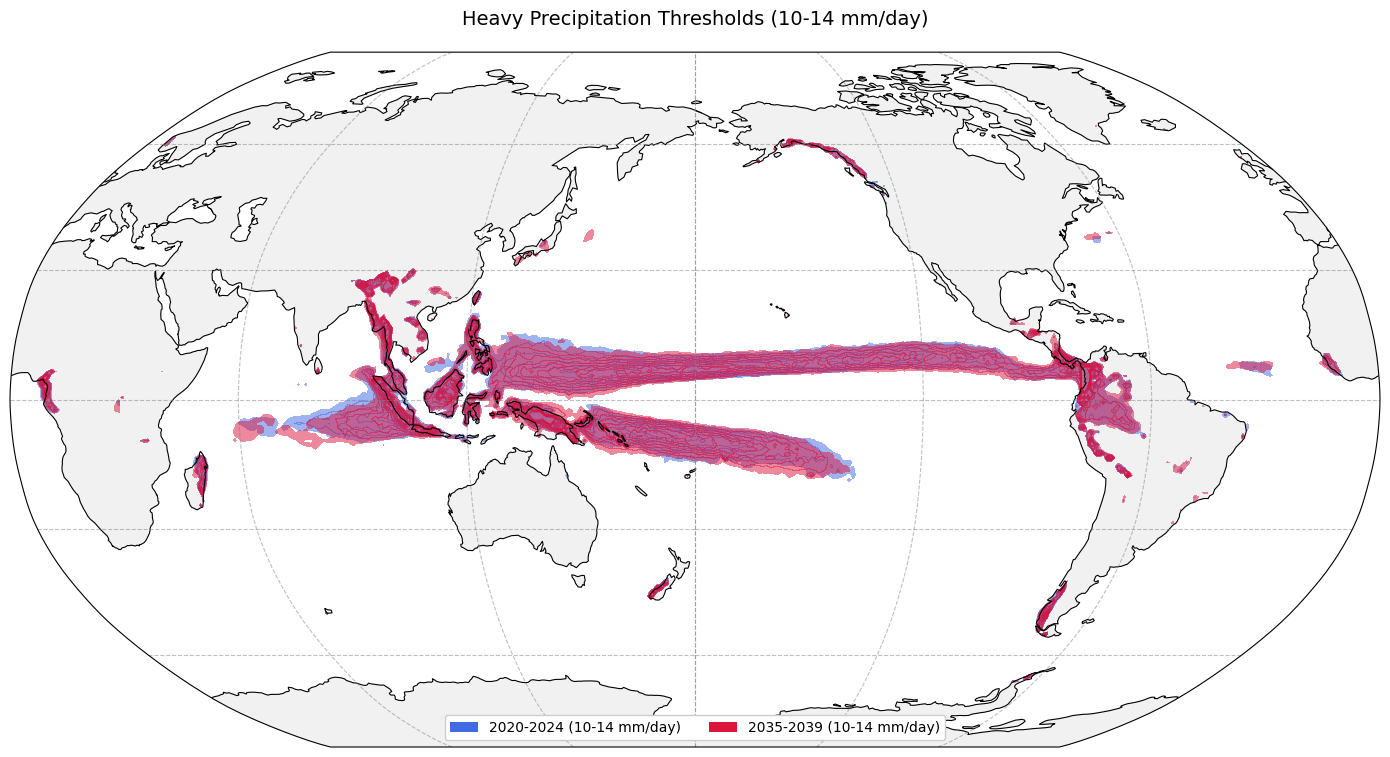

In [27]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np

# Create plot
fig = plt.figure(figsize=(14, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Custom levels (10-14 mm/day)
levels = np.arange(7, 17, 1)  

# --- Plot 2020-2024 (royalblue) ---
ax.contourf(
    grid_lon, grid_lat, grid_period1,
    levels=levels,
    transform=ccrs.PlateCarree(),
    colors=['royalblue'],
    alpha=0.5,  # Solid fill (no contours)
    extend="max"
)

# --- Plot 2035-2039 (crimson) ---
ax.contourf(
    grid_lon, grid_lat, grid_period2,
    levels=levels,
    transform=ccrs.PlateCarree(),
    colors=['crimson'],
    alpha=0.5,  # Solid fill (no contours)
    extend="max"
)

# --- Map elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Legend ---
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='royalblue', label='2020-2024 (10-14 mm/day)'),
    Patch(facecolor='crimson', label='2035-2039 (10-14 mm/day)'),
    #Patch(facecolor='#800080', label='Overlap (Both periods)')  # Purple mix
]
ax.legend(handles=legend_elements, loc='lower center', ncol=3, framealpha=1)

# --- Title ---
plt.title("Heavy Precipitation Thresholds (10-14 mm/day)", fontsize=14, pad=20)

plt.tight_layout()
plt.show()

/home/<username>/.local/lib/python3.10/site-packages/cartopy/mpl/geoaxes.py:1646: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)
/home/<username>/.local/lib/python3.10/site-packages/cartopy/mpl/geoaxes.py:1646: UserWarning: The following kwargs were not used by contour: 'edgecolor'
  result = super().contourf(*args, **kwargs)


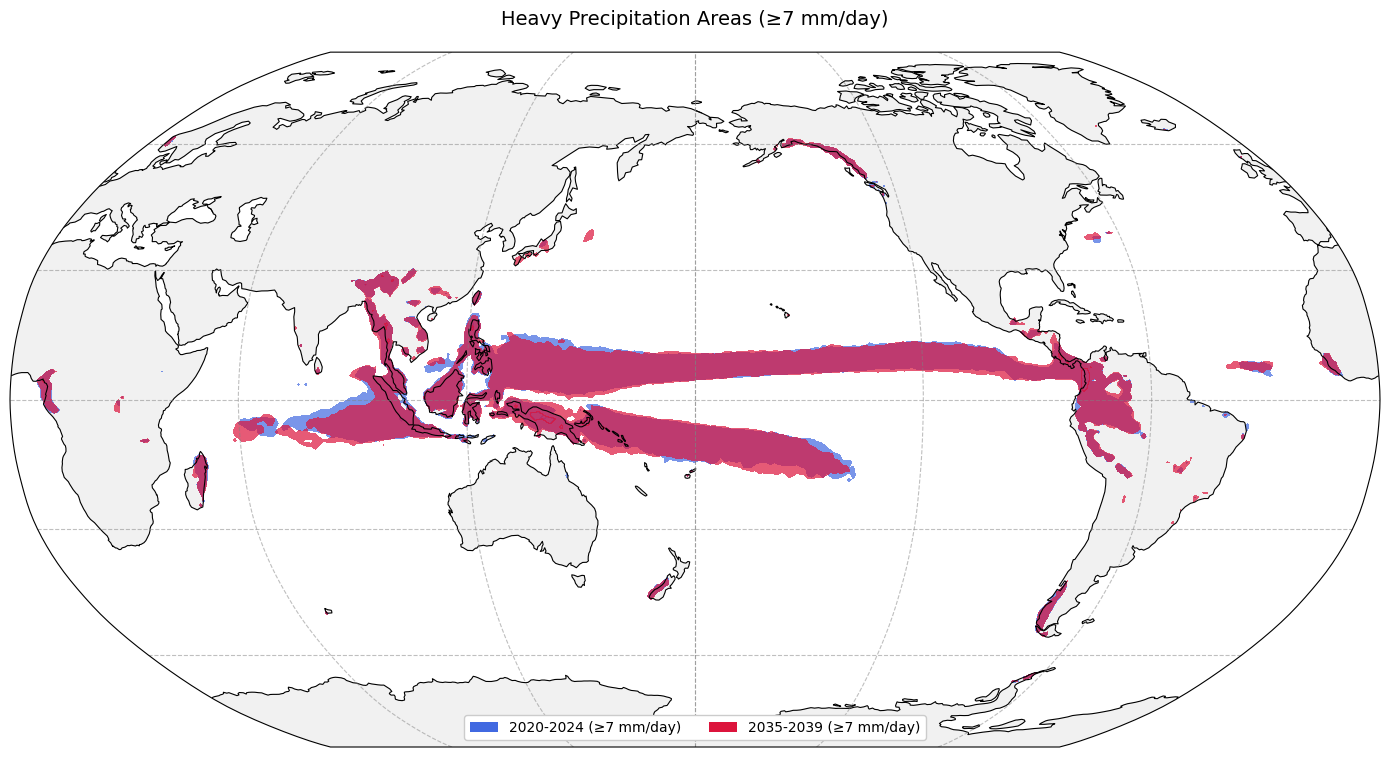

In [33]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from matplotlib.patches import Patch

# Create plot
fig = plt.figure(figsize=(14, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Custom levels (single threshold at 10 mm/day)
levels = [7, 17]  # 10 mm/day and above

# --- Plot 2020-2024 (royalblue) ---
cf1 = ax.contourf(
    grid_lon, grid_lat, grid_period1,
    levels=levels,
    transform=ccrs.PlateCarree(),
    colors=['royalblue'],
    alpha=0.7,  # Solid fill
    extend="max",
    edgecolor='face'  # This is the key parameter to remove lines
)

# --- Plot 2035-2039 (crimson) ---
cf2 = ax.contourf(
    grid_lon, grid_lat, grid_period2,
    levels=levels,
    transform=ccrs.PlateCarree(),
    colors=['crimson'],
    alpha=0.7,  # Solid fill
    extend="max",
    edgecolor='face'  # This is the key parameter to remove lines
)

# --- Map elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.LAND, facecolor='lightgray', alpha=0.3)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Legend ---
legend_elements = [
    Patch(facecolor='royalblue', label='2020-2024 (â‰¥7 mm/day)'),
    Patch(facecolor='crimson', label='2035-2039 (â‰¥7 mm/day)'),
    #Patch(facecolor='#800080', label='Both periods')
]
ax.legend(handles=legend_elements, loc='lower center', ncol=3, framealpha=1)

plt.title("Heavy Precipitation Areas (â‰¥7 mm/day)", fontsize=14, pad=20)
plt.tight_layout()
plt.show()

### Plot ITCZ 

In [12]:
# --- Calculate ITCZ Lines with Smoothing ---
def get_smoothed_itcz(precip_grid, sigma=1):
    """Returns smoothed ITCZ latitude at each longitude"""
    # First find raw ITCZ position (index of max precip at each longitude)
    itcz_idx = np.argmax(precip_grid, axis=1)  # shape: (360,)
    
    # Smooth the indices before converting to latitude
    smoothed_idx = gaussian_filter1d(itcz_idx.astype(float), sigma=sigma)
    
    # Convert indices to latitudes (-90 to 90Â°)
    return np.linspace(-90, 90, 180)[smoothed_idx.astype(int)]


from scipy.ndimage import gaussian_filter1d

# Get ITCZ positions
itcz_p1 = get_smoothed_itcz(grid_period1)  # 2020-2024
itcz_p2 = get_smoothed_itcz(grid_period2)  # 2035-2039
longitudes = np.linspace(0, 360, 360)


/tmp/ipykernel_1622582/3565980456.py:61: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


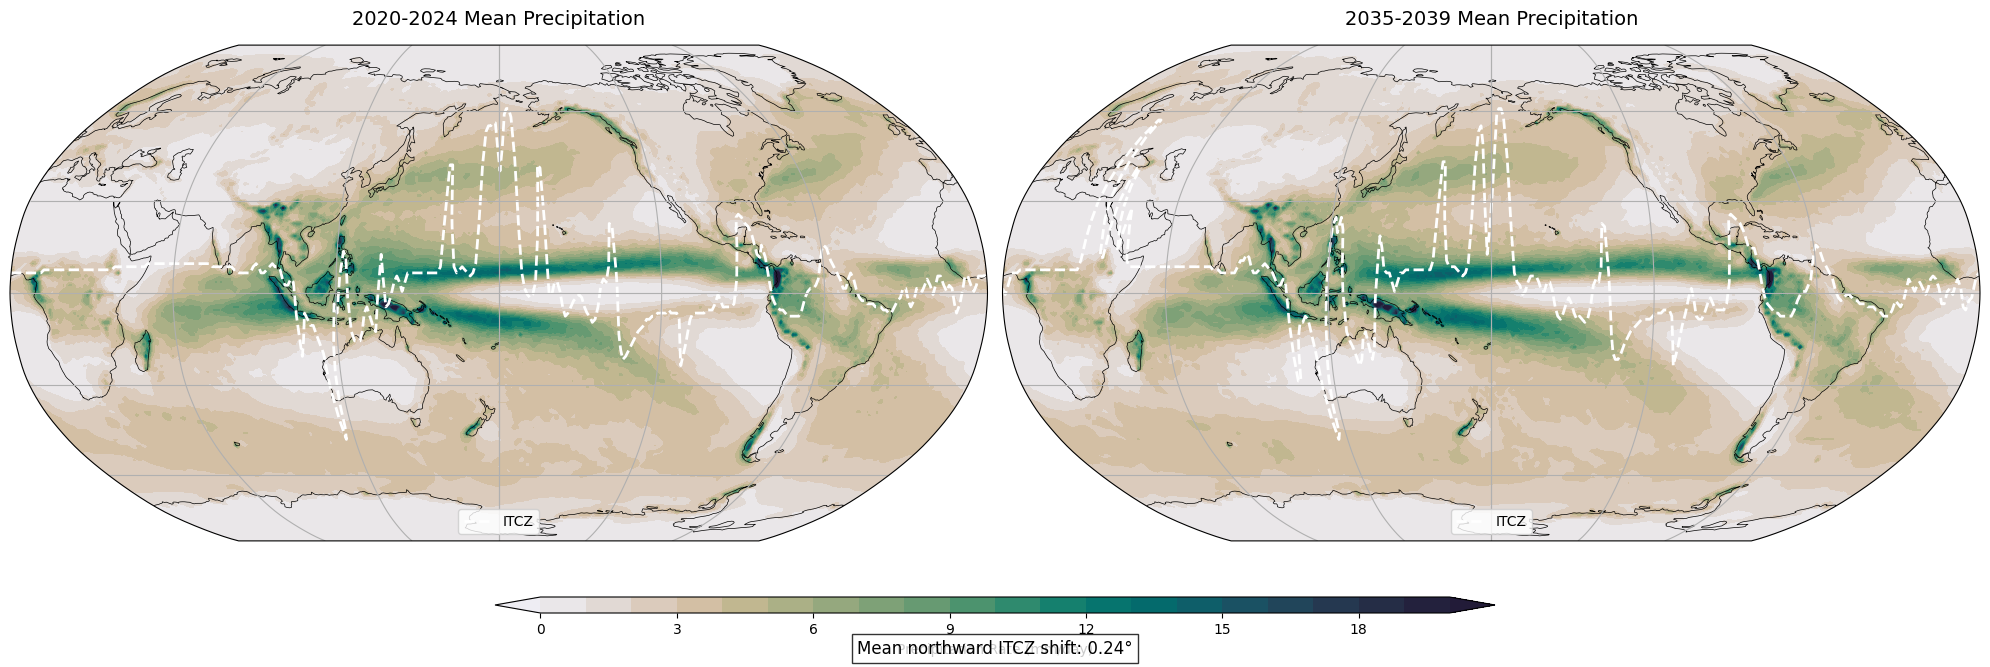

In [13]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8),
                              subplot_kw={'projection': ccrs.Robinson(central_longitude=180)})

# Common parameters for both plots
levels = np.linspace(0, 20, 21)
cmap = cmo.rain

# --- Plot 2020-2024 ---
precip1 = ax1.contourf(
    grid_lon, grid_lat, grid_period1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="both"
)

# Overlay ITCZ line
ax1.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
         color='white', linewidth=2, linestyle='--', label='ITCZ')

ax1.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax1.gridlines()
ax1.set_title("2020-2024 Mean Precipitation", fontsize=14, pad=15)
ax1.legend(loc='lower center')

# --- Plot 2035-2039 ---
precip2 = ax2.contourf(
    grid_lon, grid_lat, grid_period2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="both"
)

# Overlay ITCZ line
ax2.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
         color='white', linewidth=2, linestyle='--', label='ITCZ')

ax2.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax2.gridlines()
ax2.set_title("2035-2039 Mean Precipitation", fontsize=14, pad=15)
ax2.legend(loc='lower center')

# --- Add colorbar ---
cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.02])
cbar = fig.colorbar(precip1, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Precipitation Rate (mm/day)")

# --- Add shift annotation ---
mean_shift = np.mean(itcz_p2 - itcz_p1)
fig.text(0.5, 0.05, f"Mean northward ITCZ shift: {mean_shift:.2f}Â°", 
         ha='center', fontsize=12,
         bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

/tmp/ipykernel_1622582/521825588.py:69: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


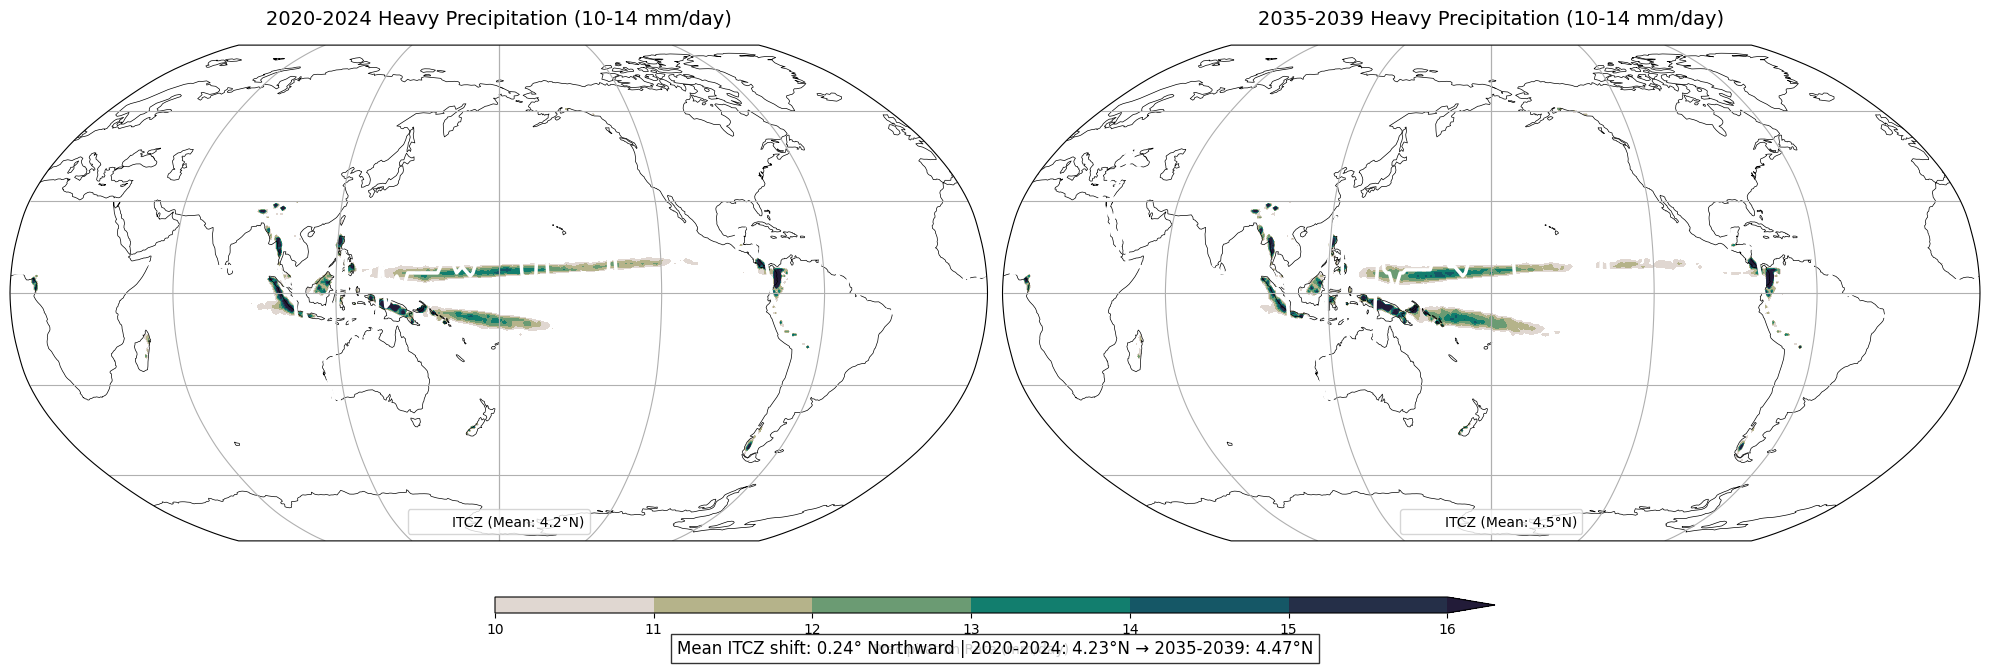

In [15]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo
import numpy as np

# Create figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8),
                              subplot_kw={'projection': ccrs.Robinson(central_longitude=180)})

# Custom contour levels (only 10-14 mm/day)
levels = np.arange(10, 17, 1)  # [10, 11, 12, 13, 14]
cmap = cmo.rain

# --- Plot 2020-2024 ---
precip1 = ax1.contourf(
    grid_lon, grid_lat, grid_period1,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="max"  # Only extend upper range since we're showing thresholds
)

# Overlay ITCZ line (thicker for visibility)
ax1.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
         color='white', linewidth=2.5, linestyle='-', 
         label=f'ITCZ (Mean: {np.mean(itcz_p1):.1f}Â°N)')

ax1.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax1.gridlines()
ax1.set_title("2020-2024 Heavy Precipitation (10-14 mm/day)", fontsize=14, pad=15)
ax1.legend(loc='lower center')

# --- Plot 2035-2039 ---
precip2 = ax2.contourf(
    grid_lon, grid_lat, grid_period2,
    transform=ccrs.PlateCarree(),
    cmap=cmap,
    levels=levels,
    extend="max"
)

# Overlay ITCZ line
ax2.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
         color='white', linewidth=2.5, linestyle='-',
         label=f'ITCZ (Mean: {np.mean(itcz_p2):.1f}Â°N)')

ax2.add_feature(cfeature.COASTLINE, linewidth=0.5)
ax2.gridlines()
ax2.set_title("2035-2039 Heavy Precipitation (10-14 mm/day)", fontsize=14, pad=15)
ax2.legend(loc='lower center')

# --- Add colorbar ---
cbar_ax = fig.add_axes([0.25, 0.1, 0.5, 0.02])
cbar = fig.colorbar(precip1, cax=cbar_ax, orientation="horizontal")
cbar.set_label("Precipitation Rate (mm/day)")
cbar.set_ticks(levels)  # Only show the levels we plotted

# --- Add shift annotation ---
mean_shift = np.mean(itcz_p2 - itcz_p1)
shift_dir = "North" if mean_shift >= 0 else "South"
fig.text(0.5, 0.05, 
         f"Mean ITCZ shift: {abs(mean_shift):.2f}Â° {shift_dir}ward | "
         f"2020-2024: {np.mean(itcz_p1):.2f}Â°N â†’ "
         f"2035-2039: {np.mean(itcz_p2):.2f}Â°N",
         ha='center', fontsize=12,
         bbox=dict(facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()

### ITCZ over t2m trend

In [44]:
# --- Calculate ITCZ Lines with Smoothing ---

# Change 'sigma' for smoothing 

def get_smoothed_itcz(precip_grid, sigma=5):
    """Returns smoothed ITCZ latitude at each longitude"""
    # First find raw ITCZ position (index of max precip at each longitude)
    itcz_idx = np.argmax(precip_grid, axis=1)  # shape: (360,)
    
    # Smooth the indices before converting to latitude
    smoothed_idx = gaussian_filter1d(itcz_idx.astype(float), sigma=sigma)
    
    # Convert indices to latitudes (-90 to 90Â°)
    return np.linspace(-90, 90, 180)[smoothed_idx.astype(int)]


from scipy.ndimage import gaussian_filter1d

# Get ITCZ positions
itcz_p1 = get_smoothed_itcz(grid_period1)  # 2020-2024
itcz_p2 = get_smoothed_itcz(grid_period2)  # 2035-2039
longitudes = np.linspace(0, 360, 360)


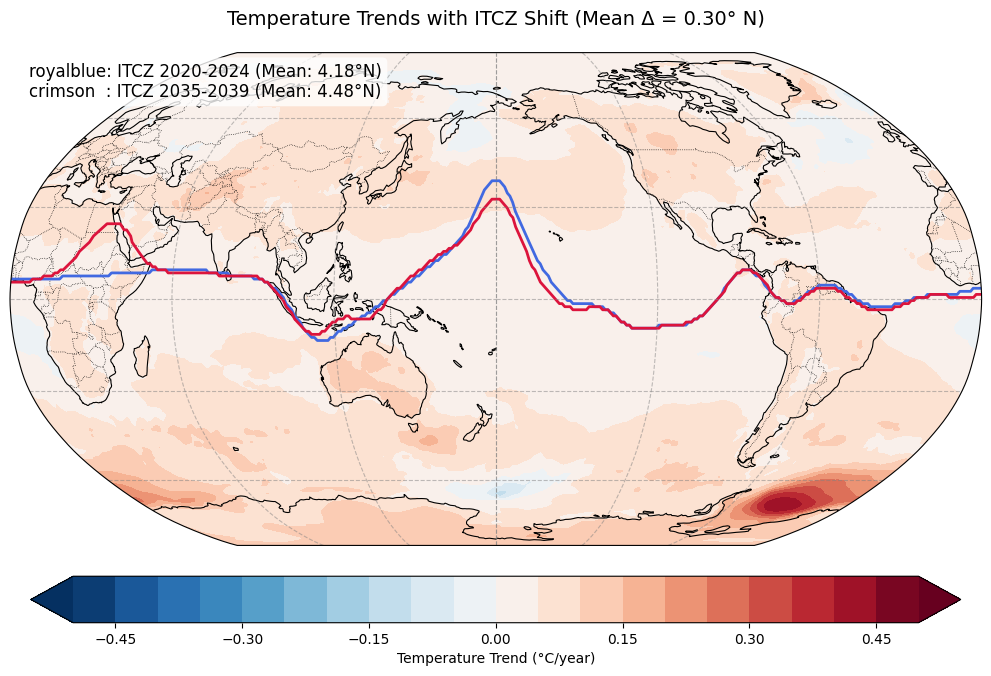

In [42]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from scipy.ndimage import gaussian_filter1d  # <-- Missing import

# Create figure
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# --- Plot Temperature Trend ---
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# --- Overlay ITCZ Lines ---
ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
        color='royalblue', linewidth=2, label='ITCZ 2020-2024')
ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
        color='crimson', linewidth=2, label='ITCZ 2035-2039')

# --- Add Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2)

# --- Add Colorbar ---
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

# --- Calculate and Display Mean Shift ---
mean_shift = np.mean(itcz_p2 - itcz_p1)
plt.title(f"Temperature Trends with ITCZ Shift (Mean Î” = {mean_shift:.2f}Â° N)", 
          fontsize=14, pad=20)

# --- Add Textbox Legend ---
legend_text = [
    f"royalblue: ITCZ 2020-2024 (Mean: {np.mean(itcz_p1):.2f}Â°N)",
    f"crimson  : ITCZ 2035-2039 (Mean: {np.mean(itcz_p2):.2f}Â°N)"
]

# Create a white semi-transparent box
textbox = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none')

# Position the text in upper left
ax.text(0.02, 0.98,  # x,y in axes coordinates (0-1)
        '\n'.join(legend_text),
        transform=ax.transAxes,
        verticalalignment='top',
        bbox=textbox,
        fontsize=12)

plt.show()

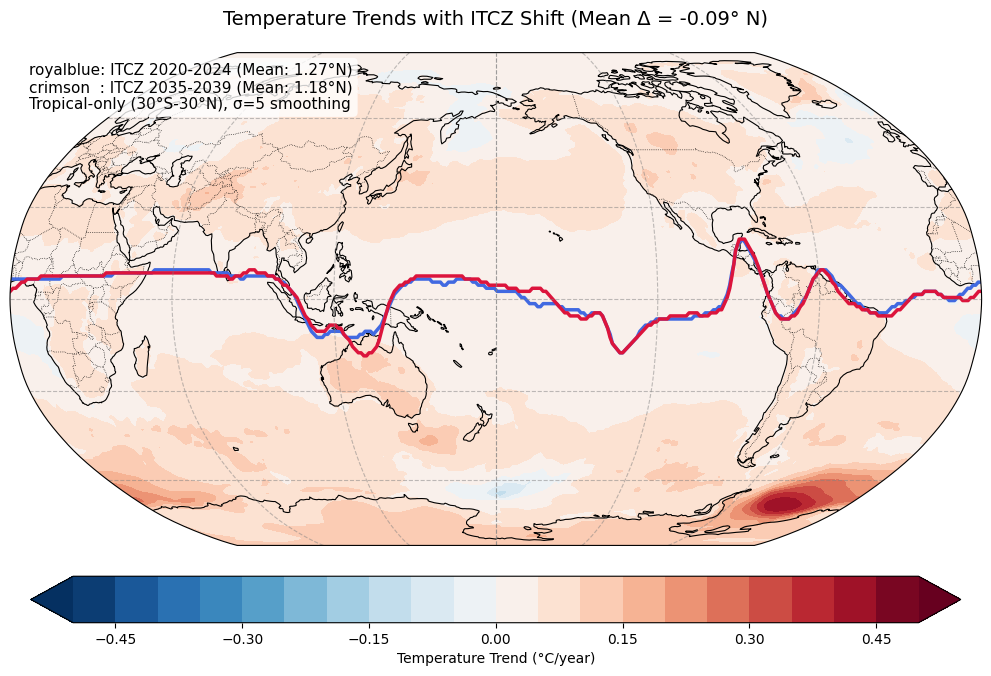

In [49]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from scipy.ndimage import gaussian_filter1d

# --- 1. TROPICAL MASKING FOR ITCZ CALCULATION ---
def get_smoothed_itcz_tropical(precip_grid, sigma=3):
    """Returns ITCZ latitude (masking extratropics >30Â°)"""
    # Create tropical mask (30Â°S to 30Â°N)
    lats = np.linspace(-90, 90, 180)
    tropical_mask = (lats >= -30) & (lats <= 30)
    
    # Mask non-tropical precipitation
    masked_precip = precip_grid.copy()
    masked_precip[:, ~tropical_mask] = 0
    
    # Find and smooth ITCZ
    itcz_idx = np.argmax(masked_precip, axis=1)
    smoothed_idx = gaussian_filter1d(itcz_idx.astype(float), sigma=sigma)
    return lats[smoothed_idx.astype(int)]

# Recalculate ITCZ with tropical masking
itcz_p1_trop = get_smoothed_itcz_tropical(grid_period1)  # 2020-2024
itcz_p2_trop = get_smoothed_itcz_tropical(grid_period2)  # 2035-2039

# --- 2. PLOTTING (YOUR ORIGINAL CODE WITH MASKED ITCZ) ---
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Temperature trend (unchanged)
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# Overlay MASKED ITCZ lines
ax.plot(longitudes, itcz_p1_trop, transform=ccrs.PlateCarree(),
        color='royalblue', linewidth=2.5, label='ITCZ 2020-2024 (Tropical)')
ax.plot(longitudes, itcz_p2_trop, transform=ccrs.PlateCarree(),
        color='crimson', linewidth=2.5, label='ITCZ 2035-2039 (Tropical)')

# --- Original map elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# --- Updated legend with tropical masking note ---
legend_text = [
    f"royalblue: ITCZ 2020-2024 (Mean: {np.mean(itcz_p1_trop):.2f}Â°N)",
    f"crimson  : ITCZ 2035-2039 (Mean: {np.mean(itcz_p2_trop):.2f}Â°N)",
    f"Tropical-only (30Â°S-30Â°N), Ïƒ=5 smoothing"
]

textbox = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none')
ax.text(0.02, 0.98, '\n'.join(legend_text),
        transform=ax.transAxes, va='top', bbox=textbox, fontsize=11)

# --- Colorbar and title ---
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

mean_shift = np.mean(itcz_p2_trop - itcz_p1_trop)
plt.title(f"Temperature Trends with ITCZ Shift (Mean Î” = {mean_shift:.2f}Â° N)", 
          fontsize=14, pad=20)

plt.show()

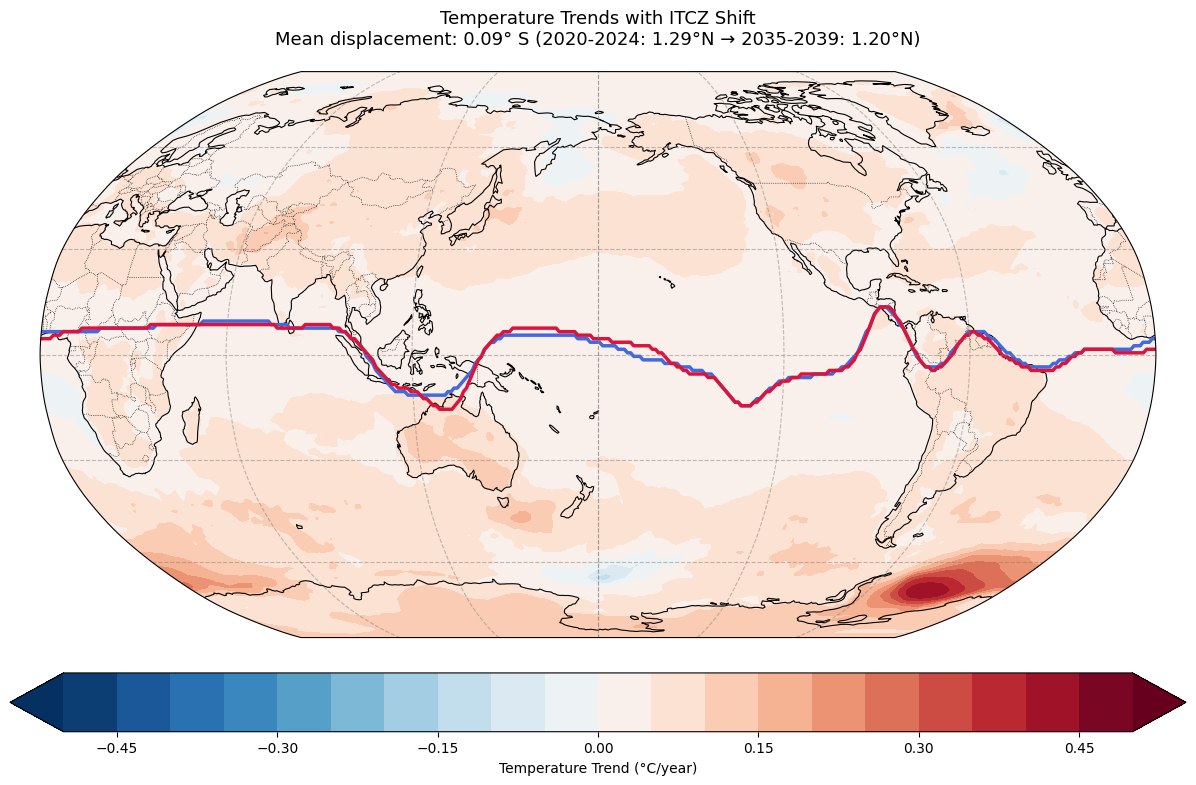

In [50]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from scipy.ndimage import gaussian_filter1d

# --- 1. Calculate ITCZ with tropical masking ---
def get_smoothed_itcz_tropical(precip_grid, sigma=5):
    """Returns ITCZ latitude (masking extratropics >30Â°)"""
    lats = np.linspace(-90, 90, 180)
    tropical_mask = (lats >= -30) & (lats <= 30)
    masked_precip = precip_grid.copy()
    masked_precip[:, ~tropical_mask] = 0  # Zero out non-tropical areas
    itcz_idx = np.argmax(masked_precip, axis=1)
    smoothed_idx = gaussian_filter1d(itcz_idx.astype(float), sigma=sigma)
    return lats[smoothed_idx.astype(int)]

# Get ITCZ positions
itcz_p1 = get_smoothed_itcz_tropical(grid_period1)  # 2020-2024
itcz_p2 = get_smoothed_itcz_tropical(grid_period2)  # 2035-2039

# --- 2. Calculate shift direction ---
mean_shift = np.mean(itcz_p2 - itcz_p1)
shift_direction = "N" if mean_shift >= 0 else "S"

# --- 3. Plotting ---
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Temperature trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# Plot ITCZ lines
ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
        color='royalblue', linewidth=2.5, label='2020-2024')
ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
        color='crimson', linewidth=2.5, label='2035-2039')

# Map elements
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Dynamic title with shift direction
plt.title(
    f"Temperature Trends with ITCZ Shift\n"
    f"Mean displacement: {abs(mean_shift):.2f}Â° {shift_direction} "
    f"(2020-2024: {np.mean(itcz_p1):.2f}Â°N â†’ "
    f"2035-2039: {np.mean(itcz_p2):.2f}Â°N)",
    fontsize=13, pad=20
)

# Colorbar
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

# Legend with white background
legend = ax.legend(
    loc='lower center',
    bbox_to_anchor=(0.5, -0.15),
    ncol=2,
    framealpha=1,
    edgecolor='black'
)

plt.tight_layout()
plt.show()

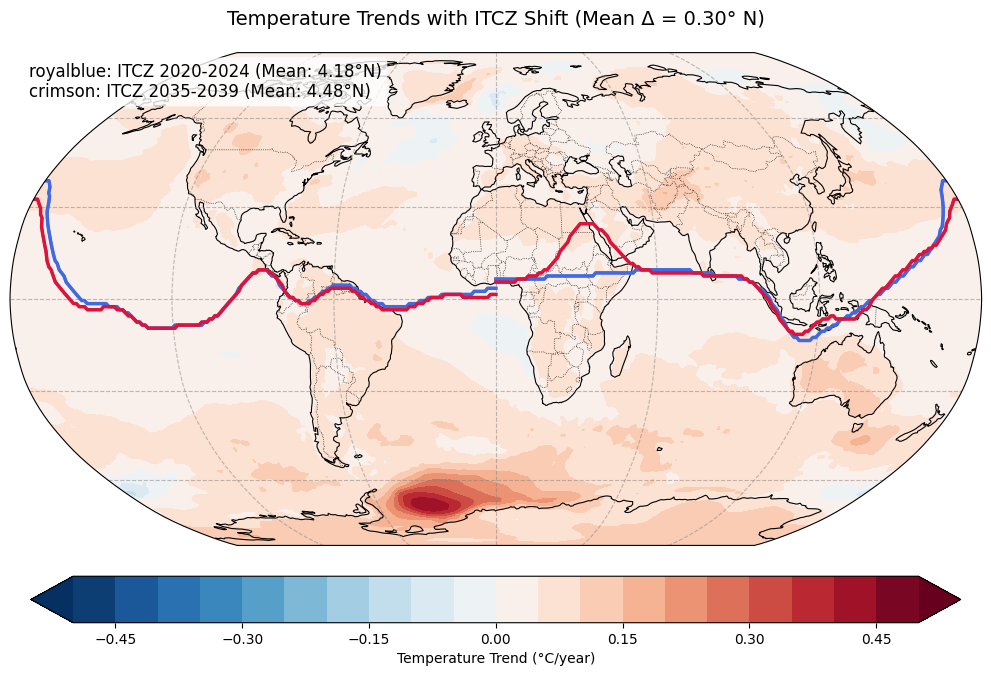

In [39]:
# Create figure
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson())

# --- Plot Temperature Trend ---
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# Get ITCZ positions
itcz_p1 = get_smoothed_itcz(grid_period1)  # 2020-2024
itcz_p2 = get_smoothed_itcz(grid_period2)  # 2035-2039
longitudes = np.linspace(0, 360, 360)

# --- Overlay ITCZ Lines ---
ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
        color='royalblue', linewidth=2, label='ITCZ 2020-2024')
ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
        color='crimson', linewidth=2, label='ITCZ 2035-2039')

# --- Add Map Elements ---
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.15), ncol=2)

# --- Add Colorbar ---
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

# --- Calculate and Display Mean Shift ---
mean_shift = np.mean(itcz_p2 - itcz_p1)
plt.title(f"Temperature Trends with ITCZ Shift (Mean Î” = {mean_shift:.2f}Â° N)", 
          fontsize=14, pad=20)

# --- Overlay ITCZ Lines with Enhanced Labels ---
itcz_line1 = ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
                    color='royalblue', linewidth=2.5, 
                    label='ITCZ 2020-2024 (Mean: {:.2f}Â°N)'.format(np.mean(itcz_p1)))[0]

itcz_line2 = ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
                    color='crimson', linewidth=2.5, 
                    label='ITCZ 2035-2039 (Mean: {:.2f}Â°N)'.format(np.mean(itcz_p2)))[0]

# --- Add Textbox Legend ---
legend_text = [
    f"royalblue: ITCZ 2020-2024 (Mean: {np.mean(itcz_p1):.2f}Â°N)",
    f"crimson: ITCZ 2035-2039 (Mean: {np.mean(itcz_p2):.2f}Â°N)"
]

# Create a white semi-transparent box
textbox = dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none')

# Position the text in upper left
ax.text(0.02, 0.98,  # x,y in axes coordinates (0-1)
        '\n'.join(legend_text),
        transform=ax.transAxes,
        verticalalignment='top',
        bbox=textbox,
        fontsize=12)
plt.show()

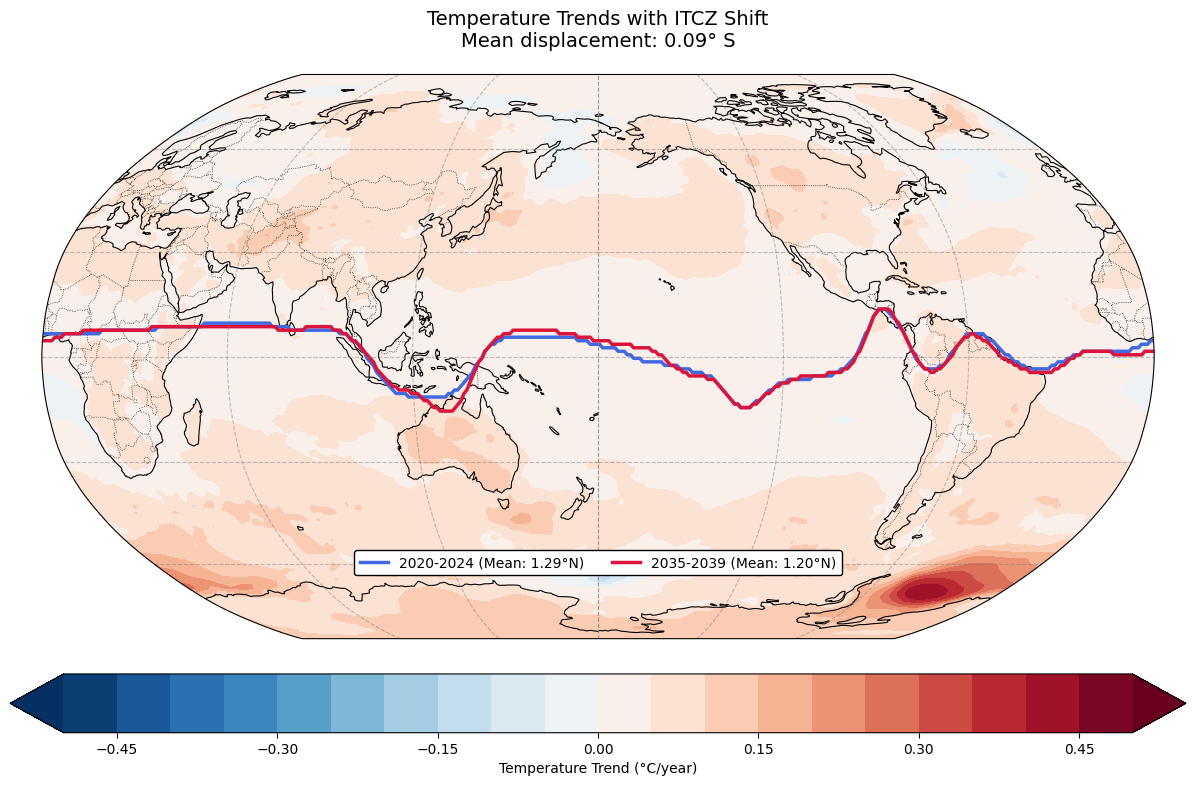

In [55]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from scipy.ndimage import gaussian_filter1d

# --- 1. Calculate ITCZ with tropical masking ---
def get_smoothed_itcz_tropical(precip_grid, sigma=5):
    """Returns ITCZ latitude (masking extratropics >30Â°)"""
    lats = np.linspace(-90, 90, 180)
    tropical_mask = (lats >= -30) & (lats <= 30)
    masked_precip = precip_grid.copy()
    masked_precip[:, ~tropical_mask] = 0
    itcz_idx = np.argmax(masked_precip, axis=1)
    smoothed_idx = gaussian_filter1d(itcz_idx.astype(float), sigma=sigma)
    return lats[smoothed_idx.astype(int)]

# Get ITCZ positions
itcz_p1 = get_smoothed_itcz_tropical(grid_period1)  # 2020-2024 (royalblue)
itcz_p2 = get_smoothed_itcz_tropical(grid_period2)  # 2035-2039 (crimson)

# --- 2. Calculate statistics ---
mean_p1 = np.mean(itcz_p1)
mean_p2 = np.mean(itcz_p2)
mean_shift = mean_p2 - mean_p1
shift_direction = "N" if mean_shift >= 0 else "S"

# --- 3. Plotting ---
fig = plt.figure(figsize=(15, 8))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Temperature trend
trend_plot = ax.contourf(
    grid_lon, grid_lat, grid_trend,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=np.linspace(-0.5, 0.5, 21),
    extend="both"
)

# Plot ITCZ lines with explicit color-period mapping
line1 = ax.plot(longitudes, itcz_p1, transform=ccrs.PlateCarree(),
                color='royalblue', linewidth=2.5, 
                label=f'2020-2024 (Mean: {mean_p1:.2f}Â°N)')[0]
line2 = ax.plot(longitudes, itcz_p2, transform=ccrs.PlateCarree(),
                color='crimson', linewidth=2.5, 
                label=f'2035-2039 (Mean: {mean_p2:.2f}Â°N)')[0]

# Map elements
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Title with shift info
plt.title(
    f"Temperature Trends with ITCZ Shift\n"
    f"Mean displacement: {abs(mean_shift):.2f}Â° {shift_direction}",
    fontsize=14, pad=20
)

# Colorbar
cbar = plt.colorbar(trend_plot, ax=ax, orientation='horizontal', 
                    pad=0.05, shrink=0.8)
cbar.set_label("Temperature Trend (Â°C/year)")

# Enhanced legend with color-period mapping
legend = ax.legend(
    handles=[line1, line2],
    loc='lower center',
    bbox_to_anchor=(0.5, 0.1),
    ncol=2,
    framealpha=1,
    edgecolor='black',
    #title='ITCZ Position (color â†” period)',
    title_fontsize=12
)

plt.tight_layout()
plt.show()

# MSLP & t2m trend

In [2]:
# # Load and Verify MSL Trend Data

msl_trend_path = f"{PROJ2559_DIR}/sfc_hr/mn_means_sfc_msl/msl_trend_2020_2039.nc"
msl_trend = xr.open_dataset(msl_trend_path)['msl_trend']

# Print dataset info
print("MSL Trend Data Structure:")
print(msl_trend)

# Check basic statistics
print("\nMSL Trend Statistics:")
print(f"Global mean: {msl_trend.mean().values:.4f} hPa/year")
print(f"Minimum: {msl_trend.min().values:.4f} hPa/year")
print(f"Maximum: {msl_trend.max().values:.4f} hPa/year")


MSL Trend Data Structure:
<xarray.DataArray 'msl_trend' (values: 196608)>
[196608 values with dtype=float32]
Dimensions without coordinates: values
Attributes:
    units:        hPa/year
    description:  Linear trend in annual mean MSLP (2020-2039)
    method:       Least-squares regression

MSL Trend Statistics:
Global mean: -0.0037 hPa/year
Minimum: -0.1413 hPa/year
Maximum: 0.1379 hPa/year


In [8]:
# Load the trend map for 2020â€“2039
t2m_trend_path = xr.open_dataset(f"{PROJ2559_DIR}/sfc_hr/t2m_trend_2020_2039.nc")["t2m_trend"]

# Print dataset info
print("T2M Trend Data Structure:")
print(t2m_trend_path)

# Check basic statistics
print("\nT2M Trend Statistics:")
print(f"Global mean: {t2m_trend_path.mean().values:.4f} Â°C/year")
print(f"Minimum: {t2m_trend_path.min().values:.4f} Â°C/year")
print(f"Maximum: {t2m_trend_path.max().values:.4f} Â°C/year")

T2M Trend Data Structure:
<xarray.DataArray 't2m_trend' (values: 196608)>
[196608 values with dtype=float64]
Coordinates:
  * values   (values) int64 0 1 2 3 4 5 ... 196603 196604 196605 196606 196607
Attributes:
    units:    Â°C/year

T2M Trend Statistics:
Global mean: 0.0522 Â°C/year
Minimum: -0.1144 Â°C/year
Maximum: 0.4447 Â°C/year


In [9]:
import numpy as np
import xarray as xr
import healpy as hp
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean.cm as cmo

# Define target grid (adjust resolution if needed)
grid_lon, grid_lat = np.meshgrid(np.linspace(-180, 180, 360), 
                                np.linspace(-90, 90, 180))

# Interpolation function for HEALPix data
def interpolate_healpix(data):
    grid = np.zeros_like(grid_lat)
    for i, j in np.ndindex(grid_lon.shape):
        grid[i, j] = hp.get_interp_val(
            data.values,
            grid_lon[i, j],
            grid_lat[i, j],
            lonlat=True,
            nest=True
        )
    return grid

# Interpolate both fields
t2m_grid = interpolate_healpix(t2m_trend_path)
msl_grid = interpolate_healpix(msl_trend)

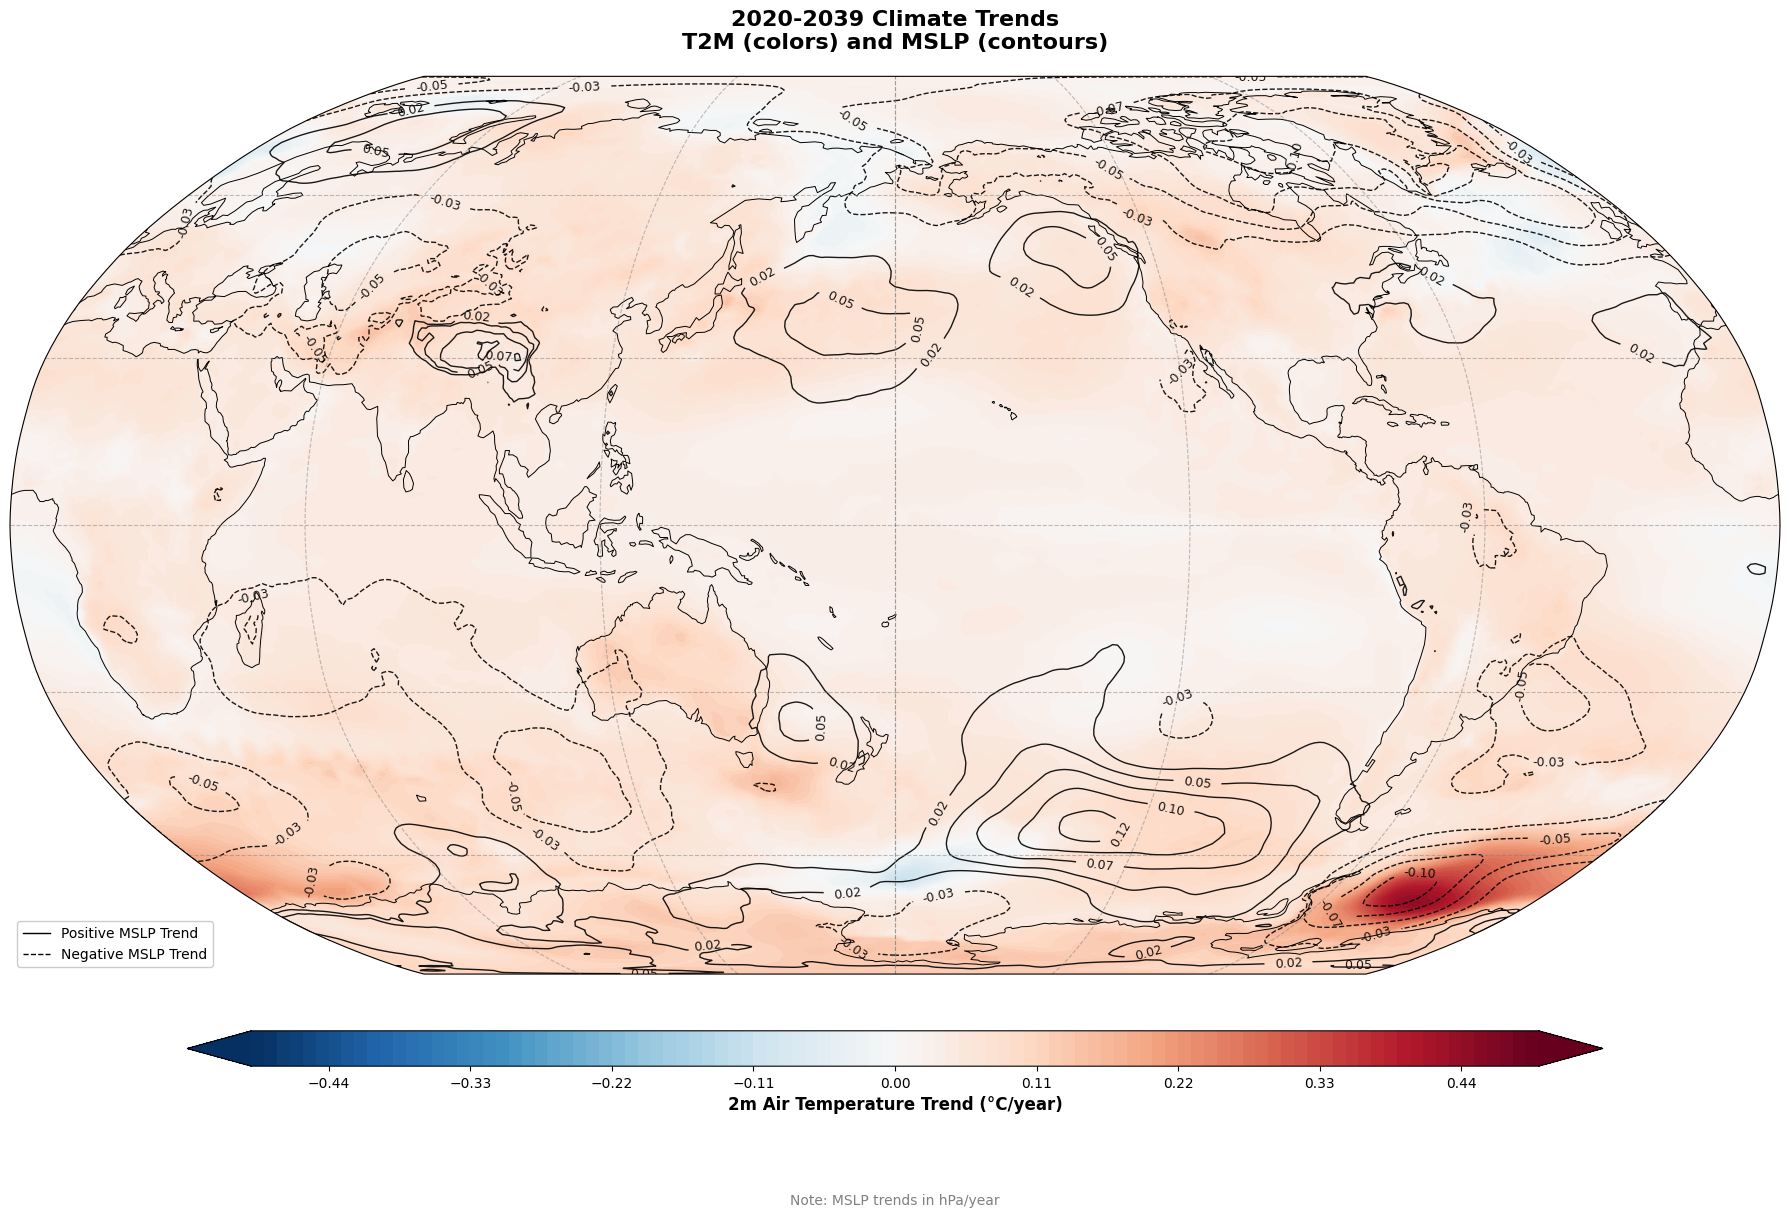

In [19]:
# Set up the figure
fig = plt.figure(figsize=(18, 12))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Plot T2M trend (colors)
t2m_plot = ax.contourf(
    grid_lon, grid_lat, t2m_grid,
    transform=ccrs.PlateCarree(),
    cmap='RdBu_r', #cmo.balance,  # Use a diverging colormap
    levels=np.linspace(-0.5, 0.5, 101),  # Adjust levels for temperature
    extend='both'
)

# Plot MSL trends as contours
# Positive contours (solid lines)
cont_pos = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='black',
    linewidths=1.0,
    levels=np.linspace(0, 0.15, 7)[1:],  # Positive values only
    linestyles='solid',
    alpha=0.9
)

# Negative contours (dashed lines)
cont_neg = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='black',
    linewidths=1.0,
    levels=np.linspace(-0.15, 0, 7)[:-1],  # Negative values only
    linestyles='dashed',
    alpha=0.9
)

# Add contour labels (every other contour)
ax.clabel(cont_pos, inline=True, fontsize=9, fmt='%1.2f')
ax.clabel(cont_neg, inline=True, fontsize=9, fmt='%1.2f')

# Add map features
ax.add_feature(cfeature.LAND, color='whitesmoke', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.7)
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Colorbar for T2M
cbar = plt.colorbar(t2m_plot, orientation='horizontal', pad=0.05, shrink=0.8, aspect=40)
cbar.set_label('2m Air Temperature Trend (Â°C/year)', fontsize=12, weight='bold')
cbar.ax.tick_params(labelsize=10)

# Legend for MSL contours
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='black', lw=1, linestyle='solid', label='Positive MSLP Trend'),
    Line2D([0], [0], color='black', lw=1, linestyle='dashed', label='Negative MSLP Trend')
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=10, framealpha=1)

# Title and annotations
plt.title('2020-2039 Climate Trends\nT2M (colors) and MSLP (contours)', 
          fontsize=16, pad=20, weight='bold')
plt.figtext(0.5, 0.01, 'Note: MSLP trends in hPa/year', 
            ha='center', fontsize=10, color='gray')

plt.tight_layout()
plt.show()

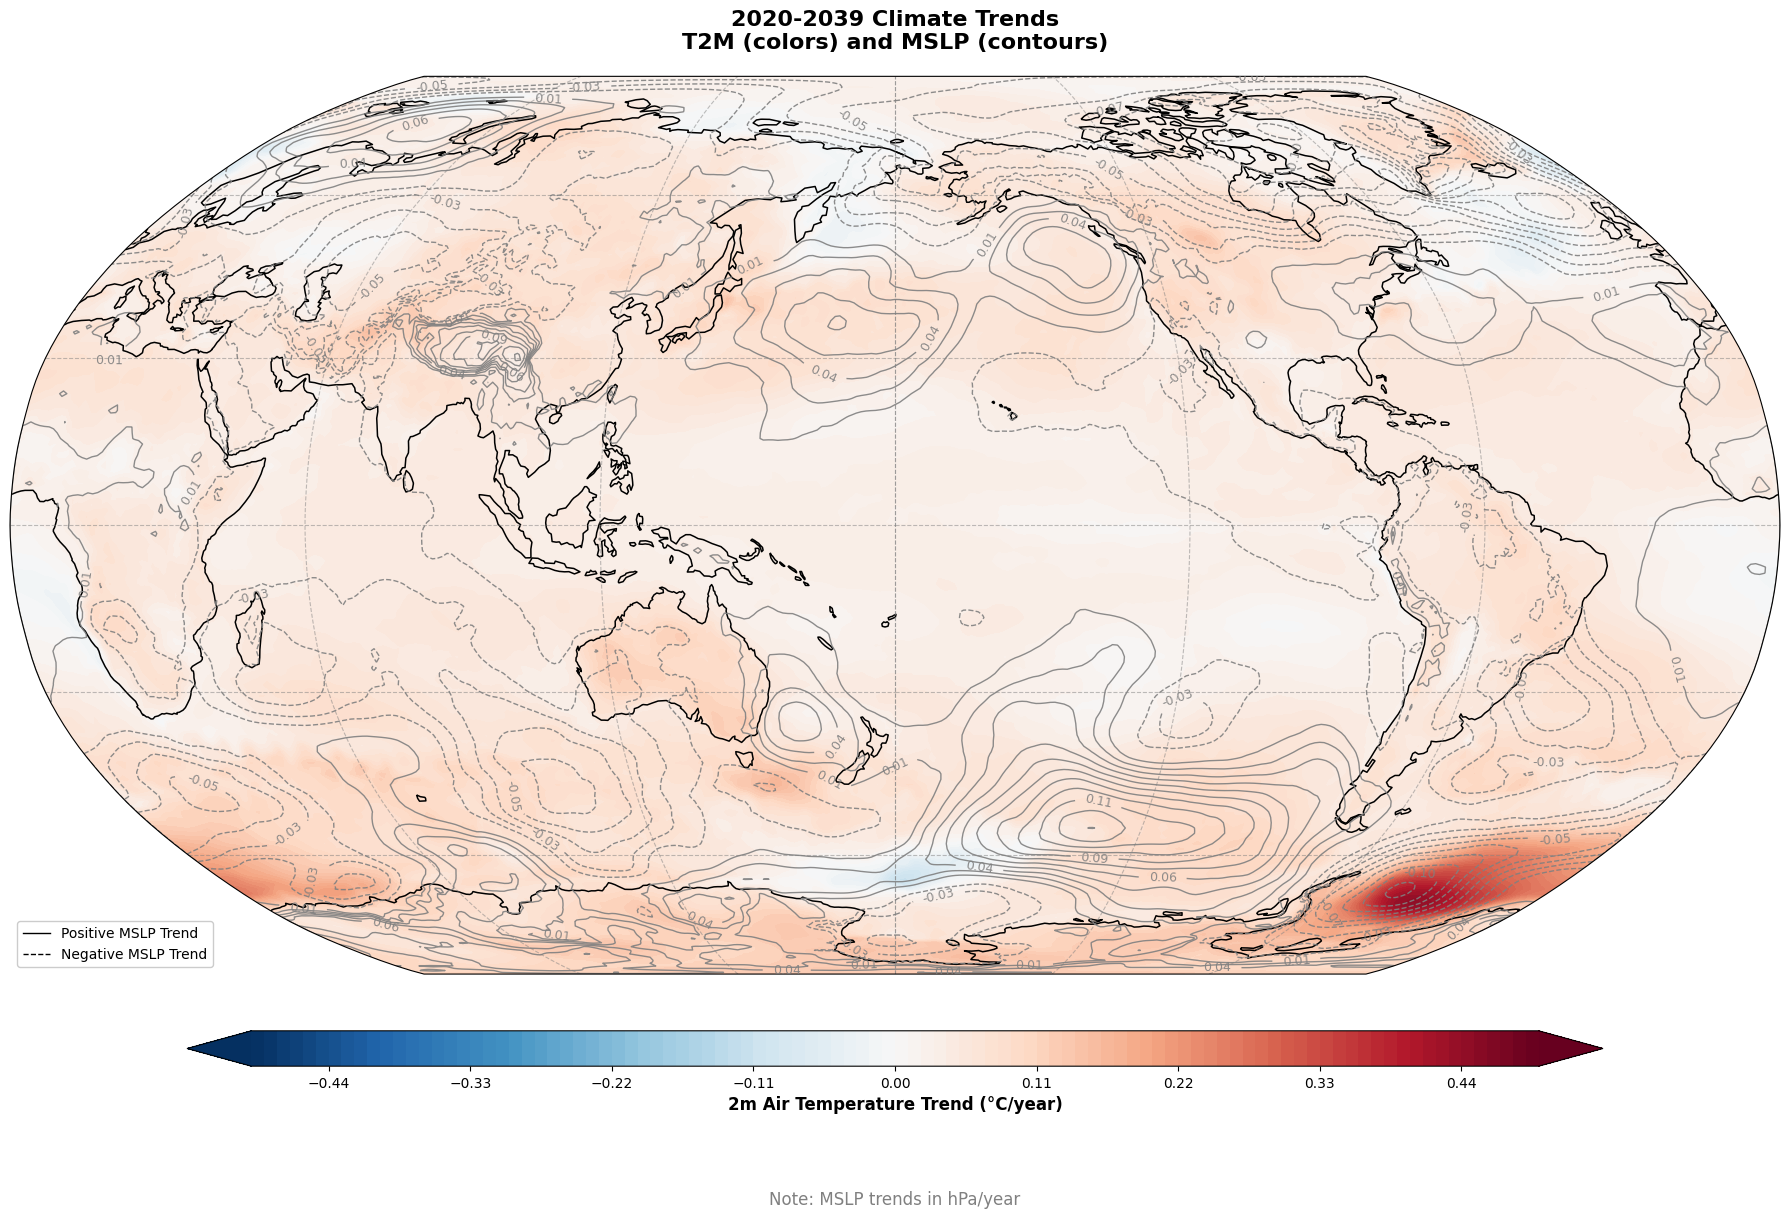

In [22]:
# Set up the figure
fig = plt.figure(figsize=(18, 12))
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))

# Plot T2M trend (colors)
t2m_plot = ax.contourf(
    grid_lon, grid_lat, t2m_grid,
    transform=ccrs.PlateCarree(),
    cmap= 'RdBu_r', #cmo.balance,
    levels=np.linspace(-0.5, 0.5, 101),
    extend='both'
)

# ---------- MODIFICATION 1: More MSL contours ----------
# Positive contours (solid lines, doubled levels)
cont_pos = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='gray',
    linewidths=1.0,
    levels=np.linspace(0, 0.15, 13)[1:],  # Now 12 levels (originally 6)
    linestyles='solid',
    alpha=0.9
)

# Negative contours (dashed lines, doubled levels)
cont_neg = ax.contour(
    grid_lon, grid_lat, msl_grid,
    transform=ccrs.PlateCarree(),
    colors='gray',
    linewidths=1.0,
    levels=np.linspace(-0.15, 0, 13)[:-1],  # Now 12 levels (originally 6)
    linestyles='dashed',
    alpha=0.9
)

# Label contours (every 2nd to avoid clutter)
ax.clabel(cont_pos, cont_pos.levels[::2], inline=True, fontsize=9, fmt='%1.2f')  # Label every other
ax.clabel(cont_neg, cont_neg.levels[::2], inline=True, fontsize=9, fmt='%1.2f')

# ---------- MODIFICATION 2: Change coastline color ----------
ax.add_feature(cfeature.LAND, color='whitesmoke', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=1.1, edgecolor='black')  # Changed to gray
ax.gridlines(color='gray', linestyle='--', alpha=0.5)

# Colorbar for T2M
cbar = plt.colorbar(t2m_plot, orientation='horizontal', pad=0.05, shrink=0.8, aspect=40)
cbar.set_label('2m Air Temperature Trend (Â°C/year)', fontsize=12, weight='bold')
cbar.ax.tick_params(labelsize=10)

# Legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='black', lw=1, linestyle='solid', label='Positive MSLP Trend'),
    Line2D([0], [0], color='black', lw=1, linestyle='dashed', label='Negative MSLP Trend')
]
ax.legend(handles=legend_elements, loc='lower left', fontsize=10, framealpha=1)

# Title
plt.title('2020-2039 Climate Trends\nT2M (colors) and MSLP (contours)', fontsize=16, pad=20, weight='bold')
plt.figtext(0.5, 0.01, 'Note: MSLP trends in hPa/year', ha='center', fontsize=12, color='gray')

plt.tight_layout()
plt.show()

# Climatology Comparison

## ERA till 2023

In [ ]:
# Loading and Preprocessing ERA5 Data

dset_2023 = xr.open_dataset(f'{ERA5_DIR}/E5sf00_1M_1940-2023_167_st_r1440x721.nc')

dset_2023.coords['lon'] = (dset_2023.coords['lon'] + 180) % 360 - 180
dset_2023 = dset_2023.sortby(dset_2023.lon)

data_era_2t_2023 = dset_2023['var167'] - 273.15

In [ ]:
dset_2023['var167'].attrs

In [ ]:
dset_2023.attrs

### Climatology 1994-2023

In [ ]:
# Calculating Climatology (1994â€“2023)
data_era2t_clim_23 = data_era_2t_2023.sel(time=slice('1994', '2023')).mean('time')
data_era2t_clim_23

In [ ]:
# Interpolating ERA5 Data to Model Grid

import numpy as np
from scipy.interpolate import RegularGridInterpolator

# Define your model grid (180x360)
model_lat = np.linspace(-90, 90, 180)
model_lon = np.linspace(-180, 180, 360)
model_lon_grid, model_lat_grid = np.meshgrid(model_lon, model_lat)

# Extract ERA5 latitude and longitude
era5_lat = data_era2t_clim_23.lat.values
era5_lon = data_era2t_clim_23.lon.values

# Create an interpolator for the ERA5 data
era5_interpolator = RegularGridInterpolator(
    (era5_lat, era5_lon),  # Input grid (latitude, longitude)
    data_era2t_clim_23.values,  # Input data
    method="linear",  # Interpolation method
    bounds_error=False,  # Allow extrapolation
    fill_value=np.nan,  # Fill value for extrapolation
)

# Interpolate ERA5 data to the model grid
era5_interpolated_clim_23 = era5_interpolator((model_lat_grid, model_lon_grid))

# Check the interpolated data
print(f"Interpolated ERA5 values min: {np.nanmin(era5_interpolated_clim_23)}, max: {np.nanmax(era5_interpolated_clim_23)}")

In [ ]:
# Plotting the Interpolated Data

import cartopy.crs as ccrs
import matplotlib.pyplot as plt

# Create a figure
fig = plt.figure(figsize=(12, 6))
ax = plt.axes(projection=ccrs.Robinson())

# Plot the interpolated ERA5 data
era5_interp_plot = ax.contourf(
    model_lon_grid, model_lat_grid, era5_interpolated_clim_23,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",  # Colormap for temperature
    levels=100,       # Number of color levels
)

# Add coastlines and gridlines
ax.coastlines()
ax.gridlines()

# Add a colorbar
cbar = plt.colorbar(era5_interp_plot, ax=ax, orientation="horizontal", pad=0.05)
cbar.set_label("2m Temperature (Â°C)", fontsize=12)

# Add a title
plt.title(f"ERA5 2m Temperature: 1994 - 2023", fontsize=14)

# Show the plot
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from matplotlib.colors import BoundaryNorm, LinearSegmentedColormap

# Create figure
fig = plt.figure(figsize=(12, 6))

# Define the projection
ax = plt.axes(projection=ccrs.Robinson())

# Define levels for the contour plot
num_levels = 41  # Number of color levels
levels = np.linspace(-40, 40, num_levels)  # Levels from -40Â°C to 40Â°C

# Plot the interpolated ERA5 data
era5_interp_plot = ax.contourf(
    model_lon_grid, model_lat_grid, era5_interpolated_clim_23,
    levels=levels,  # Use predefined levels
    cmap='RdBu_r',  # Use the reversed Red-Blue colormap
    vmin=-40,       # Set minimum value for colormap
    vmax=40,        # Set maximum value for colormap
    transform=ccrs.PlateCarree(),
    extend='both',  # Extend colormap to show values outside the range
)

# Add coastlines with a specified line width
ax.add_feature(cfeature.COASTLINE, linewidth=0.5)

# Add a title
ax.set_title("ERA5 2m Temperature Climatology: 1994 - 2023", fontsize=14)

# Add a colorbar with better positioning
cbar_ax = fig.add_axes([0.16, 0.05, 0.7, 0.03])  # [left, bottom, width, height]
cbar = fig.colorbar(era5_interp_plot, cax=cbar_ax, orientation='horizontal')
cbar.set_label("2m Temperature (Â°C)", fontsize=12)

# Show the plot
plt.show()

# Error